In [1]:
import pandas as pd
application_df = pd.read_csv('IS453 Group Assignment - Data/IS453 Group Assignment - Application Data.csv')
bureau_df = pd.read_csv('IS453 Group Assignment - Data/IS453 Group Assignment - Bureau Data.csv')

# Week 7 Preparation
Unpack the file "IS453 Group Assignment - Data.zip"<BR>
Based on the data files and data dictionary, answer the questions below.

**DIY Q4: Explore Assignment Data**
- How many rows and column in each data file?
- Through which variable is the data in two files linked?
- Is the relationship between the records in the files one-to-one or one-to-many? In which direction?
- Are all of the records in each file linked to the other? If not, which file has unlinked records?
- Which variables would potentially conflict with fair lending principles?

**Answers**
- **Size:** Application 307,511 rows x 120 columns; Bureau 1,716,428 rows x 17 columns.
- **Link:** `SK_ID_CURR`.
- **Relationship:** one-to-many, from Application to Bureau. `SK_ID_CURR` is unique in Application, while Bureau has 1 to 116 rows per ID (mean 5.6, median 4). `SK_ID_BUREAU` is unique per Bureau row.
- **Unlinked records:** Not all records link. 263,491 IDs appear in both files. 44,020 application IDs have no bureau history (these need a "no bureau record" flag/treatment after the merge). 42,320 bureau IDs have no application row, so these are unusable for modelling.
- **Fair lending concerns:** `CODE_GENDER`, `DAYS_BIRTH` (age), `NAME_FAMILY_STATUS`, `CNT_CHILDREN`, `CNT_FAM_MEMBERS` (family status/dependants), `NAME_EDUCATION_TYPE` (possible proxy), `REGION_POPULATION_RELATIVE`, `REGION_RATING_CLIENT(_W_CITY)` and the housing-block variables (geographic proxies / redlining risk), `ORGANIZATION_TYPE` and `NAME_INCOME_TYPE` (e.g. maternity leave), `NAME_TYPE_SUITE`, and the `*_CNT_SOCIAL_CIRCLE` variables (judged on others' behaviour, not the applicant's).

In [2]:
print('Application:', application_df.shape, '| Bureau:', bureau_df.shape)

app_ids, bur_ids = set(application_df.SK_ID_CURR), set(bureau_df.SK_ID_CURR)
print('Application IDs with no bureau record:', len(app_ids - bur_ids))
print('Bureau IDs with no application record:', len(bur_ids - app_ids))
print('Overall bad rate:', application_df.TARGET.mean()*100)

Application: (307511, 120) | Bureau: (1716428, 17)


Application IDs with no bureau record: 44020
Bureau IDs with no application record: 42320
Overall bad rate: 8.072881945686495


# Week 9 Preparation
Based on the group assignment data, answer the DIY question below.

**DIY Q4: Preparing the bureau data for merging**

To combine the bureau data with the application data you will need to "flatten" the multiple rows associated with each application ID (SK_ID_CURR) into a single row. <BR>
It will also be helpful if you can reduce the number of columns in the bureau data that will need to be merged.
- Based on the data dictionary definitions and the inspection of the bureau data, explain how you would propose to do feature engineering on all of the bureau variables so that they can be condensed to one value per application ID.
- Calculate the correlation between the bureau variables and use that information to further propose how columns could potentially be combined or dropped.

Put your code and answers below, and prepare to discuss in class next week.

## Step 2 – Flattening bureau data
Collapses the many bureau rows per applicant into one row per `SK_ID_CURR` (counts, maxima, sums and two ratios) so the table can be joined to the application data. It sits here in the Week 9 section, ahead of Step 1, because it does not depend on the segment filter.

In [3]:
import numpy as np

# Correlation on the raw bureau numeric columns
raw_corr = bureau_df.drop(columns=['SK_ID_CURR', 'SK_ID_BUREAU']).select_dtypes('number').corr()
print(raw_corr.round(2))

b = bureau_df.copy()
biz = ['Loan for business development', 'Loan for working capital replenishment', 'Loan for the purchase of equipment']
b['ACTIVE'] = (b.CREDIT_ACTIVE == 'Active').astype(int)
b['CLOSED'] = (b.CREDIT_ACTIVE == 'Closed').astype(int)
b['SOLD_BAD'] = b.CREDIT_ACTIVE.isin(['Sold', 'Bad debt']).astype(int)
b['CARD'] = (b.CREDIT_TYPE == 'Credit card').astype(int)
b['CONSUMER'] = (b.CREDIT_TYPE == 'Consumer credit').astype(int)
b['MORTGAGE'] = (b.CREDIT_TYPE == 'Mortgage').astype(int)
b['CAR'] = (b.CREDIT_TYPE == 'Car loan').astype(int)
b['MICRO'] = (b.CREDIT_TYPE == 'Microloan').astype(int)
b['BUSINESS'] = b.CREDIT_TYPE.isin(biz).astype(int)
b['OVERDUE_NOW'] = (b.CREDIT_DAY_OVERDUE > 0).astype(int)

bureau_flat = b.groupby('SK_ID_CURR').agg(
    BUR_N=('SK_ID_BUREAU', 'count'),
    BUR_N_ACTIVE=('ACTIVE', 'sum'), BUR_N_CLOSED=('CLOSED', 'sum'), BUR_N_SOLD_BAD=('SOLD_BAD', 'sum'),
    BUR_N_CARD=('CARD', 'sum'), BUR_N_CONSUMER=('CONSUMER', 'sum'), BUR_N_MORTGAGE=('MORTGAGE', 'sum'),
    BUR_N_CAR=('CAR', 'sum'), BUR_N_MICRO=('MICRO', 'sum'), BUR_N_BUSINESS=('BUSINESS', 'sum'),
    BUR_N_OVERDUE_NOW=('OVERDUE_NOW', 'sum'), BUR_MAX_DAYS_OVERDUE=('CREDIT_DAY_OVERDUE', 'max'),
    BUR_MAX_AMT_MAX_OVERDUE=('AMT_CREDIT_MAX_OVERDUE', 'max'), BUR_SUM_AMT_OVERDUE=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
    BUR_SUM_PROLONG=('CNT_CREDIT_PROLONG', 'sum'),
    BUR_MOST_RECENT_DAYS=('DAYS_CREDIT', 'max'), BUR_OLDEST_DAYS=('DAYS_CREDIT', 'min'),
    BUR_MAX_ENDDATE=('DAYS_CREDIT_ENDDATE', 'max'), BUR_LAST_UPDATE=('DAYS_CREDIT_UPDATE', 'max'),
    BUR_SUM_CREDIT=('AMT_CREDIT_SUM', 'sum'), BUR_SUM_DEBT=('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUR_SUM_LIMIT=('AMT_CREDIT_SUM_LIMIT', 'sum'), BUR_SUM_ANNUITY=('AMT_ANNUITY', 'sum'),
).reset_index()
bureau_flat['BUR_DEBT_RATIO'] = bureau_flat.BUR_SUM_DEBT / bureau_flat.BUR_SUM_CREDIT.replace(0, np.nan)
bureau_flat['BUR_PCT_ACTIVE'] = bureau_flat.BUR_N_ACTIVE / bureau_flat.BUR_N
print(bureau_flat.shape, 'unique IDs:', bureau_flat.SK_ID_CURR.is_unique)

# Correlation on the flattened features: list highly correlated pairs
c = bureau_flat.drop(columns='SK_ID_CURR').corr()
pairs = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack()
print(pairs[pairs.abs() > 0.8].sort_values(ascending=False).round(2))

                        DAYS_CREDIT  CREDIT_DAY_OVERDUE  DAYS_CREDIT_ENDDATE  \
DAYS_CREDIT                    1.00               -0.03                 0.23   
CREDIT_DAY_OVERDUE            -0.03                1.00                -0.01   
DAYS_CREDIT_ENDDATE            0.23               -0.01                 1.00   
DAYS_ENDDATE_FACT              0.88               -0.01                 0.25   
AMT_CREDIT_MAX_OVERDUE        -0.01                0.00                 0.00   
CNT_CREDIT_PROLONG            -0.03                0.00                 0.11   
AMT_CREDIT_SUM                 0.05               -0.00                 0.06   
AMT_CREDIT_SUM_DEBT            0.14               -0.00                 0.08   
AMT_CREDIT_SUM_LIMIT           0.03               -0.00                 0.10   
AMT_CREDIT_SUM_OVERDUE        -0.00                0.09                 0.00   
DAYS_CREDIT_UPDATE             0.69               -0.02                 0.25   
AMT_ANNUITY                    0.01     

(305811, 26) unique IDs: True


BUR_N         BUR_N_CONSUMER    0.93
              BUR_N_CLOSED      0.93
BUR_N_CLOSED  BUR_N_CONSUMER    0.92
dtype: float64


**Proposed feature engineering (one row per `SK_ID_CURR`)**

| Bureau variable | Aggregation(s) | Rationale |
|---|---|---|
| `SK_ID_BUREAU` | count -> `BUR_N` | Number of prior credit lines (credit experience / activity) |
| `CREDIT_ACTIVE` | count Active / Closed / Sold+Bad debt | Sold and Bad debt are tiny (6.5k and 21 rows), so they are merged into one count. Active share shows current exposure |
| `CREDIT_CURRENCY` | **drop** | 99.9% is "currency 1", so no information |
| `CREDIT_TYPE` | count of Card, Consumer, Mortgage, Car, Microloan, **Business** (business development + working capital + equipment) | 15 types are too many and most are rare. Business credit history is directly relevant to our small-business segment |
| `DAYS_CREDIT` | max (most recent application), min (oldest = history length) | Credit recency and length of history |
| `CREDIT_DAY_OVERDUE` | max, count of lines currently overdue | Current delinquency is the strongest risk signal |
| `AMT_CREDIT_MAX_OVERDUE` | max | Worst past delinquency (65% missing; treat missing as "no overdue recorded" and consider a flag) |
| `AMT_CREDIT_SUM_OVERDUE` | sum | Total amount currently overdue |
| `CNT_CREDIT_PROLONG` | sum | Number of extensions = possible repayment stress |
| `DAYS_CREDIT_ENDDATE` | max | Longest remaining commitment |
| `DAYS_ENDDATE_FACT` | **drop** | Only exists for closed credits, and correlated 0.88 with `DAYS_CREDIT` |
| `AMT_CREDIT_SUM` / `_DEBT` / `_LIMIT` | sum; plus ratio `DEBT/CREDIT` | Total exposure and leverage. A ratio is more comparable across applicants than raw amounts |
| `AMT_ANNUITY` | sum | Instalment burden (72% missing, so interpret with care) |
| `DAYS_CREDIT_UPDATE` | max | Freshness of bureau information |

Applicants with no bureau record (44,020) will get counts = 0 and a `NO_BUREAU` flag after the left join (to add at merge time), with other aggregates left missing for binning. This avoids confusing "no history" with "clean history".

**Correlation findings**
- On the raw data: `DAYS_CREDIT` vs `DAYS_ENDDATE_FACT` is 0.88 and `DAYS_CREDIT` vs `DAYS_CREDIT_UPDATE` is 0.69, which supports dropping `DAYS_ENDDATE_FACT`. `AMT_CREDIT_SUM` vs `AMT_CREDIT_SUM_DEBT` is 0.68, which supports using the debt ratio.
- After aggregation, run the pairs check in the code cell and drop one of any pair with |r| > 0.8. In my run, `BUR_N` vs `BUR_N_CONSUMER` (0.93) and `BUR_N` vs `BUR_N_CLOSED` (0.93) came out high. Keep `BUR_N` and use the type/status mix as shares, or drop the redundant counts.

# Week 10 Consult with Prof
**Our customer segment is: Launch small business loan**

In Week 10, each group will explain to the professor their criteria for selecting rows from the data that are representative of their customer segment and the resulting:
- number of rows
- percentage of bads in comparison to the original data set

Each group will also describe its intended approach for merging the application and bureau data sets.


## Step 1 – Filtering application data to the segment
Keeps applicants aged 18–55 with `AMT_CREDIT` under 500,000, our "Launch small business loan" segment, and compares its size and bad rate with the full data.

In [4]:
application_df = application_df.copy()     # stops pandas showing a "DataFrame is highly fragmented" warning
application_df['AGE'] = -application_df.DAYS_BIRTH / 365
segment_df = application_df[application_df.AGE.between(18, 55) & (application_df.AMT_CREDIT < 500000)].copy()
print('Rows:', len(segment_df), f'({len(segment_df) / len(application_df):.1%} of original)')
print('Bad rate: segment', f'{segment_df.TARGET.mean():.2%}', '| original', f'{application_df.TARGET.mean():.2%}')

Rows: 115022 (37.4% of original)
Bad rate: segment 9.49% | original 8.07%


## Step 3 – Merging application and bureau data
Left-joins the flattened bureau table from Step 2 onto the segment, giving one row per applicant. Applicants with no bureau record get zero counts, Missing for the other bureau fields, and a `NO_BUREAU` flag.

In [5]:
# Left-join the flattened bureau table (from the Week 9 cell) onto the segment
merged_df = segment_df.merge(bureau_flat, on='SK_ID_CURR', how='left')
merged_df['NO_BUREAU'] = merged_df.BUR_N.isna().astype(int)
count_cols = [c for c in bureau_flat.columns if c.startswith('BUR_N')]
merged_df[count_cols] = merged_df[count_cols].fillna(0)

print('Merged shape:', merged_df.shape, '| unique IDs:', merged_df.SK_ID_CURR.is_unique)
print('No bureau record:', merged_df.NO_BUREAU.sum(), f'({merged_df.NO_BUREAU.mean():.1%})')
print(merged_df.groupby('NO_BUREAU').TARGET.agg(['size', 'mean']))

Merged shape: (115022, 147) | unique IDs: True
No bureau record: 18476 (16.1%)
            size      mean
NO_BUREAU                 
0          96546  0.090610
1          18476  0.117558


**Checkpoint summary: Launch small business loan**

*Row selection criteria (both approved by the professor)*
1. **Age 18 to 55**: the realistic window for starting a business. The youngest applicant is 20.5, so the lower bound removes nobody. The 55 cap removes about 22% of rows.
2. **`AMT_CREDIT` < 500,000**: a plausible startup financing range (equipment, inventory, deposits, initial operating expenses). 500k is about the median loan, so it keeps the smaller half. It leaves 115k rows and about 11k bads, enough to model, whereas lower caps shrink the sample sharply (e.g. 150k leaves 909 bads) and higher caps add loans that look less like startup financing.

*Result*
- **Rows:** 115,022 of 307,511 (37.4% of the original data)
- **Bads:** 10,920 = **9.49%**, against 8.07% in the original data (the segment is somewhat riskier than the full book)

*Merge approach*
1. Filter the application data first.
2. Flatten the bureau data to one row per `SK_ID_CURR` (Week 9 aggregations).
3. Left-join the flattened bureau table onto the filtered applications on `SK_ID_CURR`. This keeps all 115,022 applicants. The result has one row per applicant (confirmed unique).
4. 18,476 applicants (16.1%) have no bureau record. For them the count features are set to 0, the other aggregates stay missing, and a `NO_BUREAU` flag is added. These applicants have a higher bad rate (11.8% vs 9.1% with bureau history), so the flag is informative.

*Assumptions and limitations*
- No variable records the loan purpose, so age and loan size are proxies. Not every applicant in the segment is actually starting a business.
- About 19% of the filtered loans are revolving rather than term loans.
- The amount cap biases the segment towards smaller borrowers.

In [6]:
age_ok = application_df[application_df.AGE.between(18, 55)]
base_rows = (age_ok.AMT_CREDIT < 500000).sum()

rows = []
for cap in [500000, 450000, 400000, 350000, 300000, 250000, 200000, 150000, 100000]:
    sub = age_ok[age_ok.AMT_CREDIT < cap]
    rows.append({'AMT_CREDIT <': f'{cap:,}', 'Rows': len(sub), '% of 500k sample': round(len(sub) / base_rows * 100, 1),
                 'Bads': int(sub.TARGET.sum()), 'Bad rate %': round(sub.TARGET.mean() * 100, 2)})
cap_table = pd.DataFrame(rows)
print(cap_table.to_string(index=False))

AMT_CREDIT <   Rows  % of 500k sample  Bads  Bad rate %
     500,000 115022             100.0 10920        9.49
     450,000  95803              83.3  8946        9.34
     400,000  89050              77.4  8113        9.11
     350,000  81053              70.5  7252        8.95
     300,000  68103              59.2  5839        8.57
     250,000  44331              38.5  3628        8.18
     200,000  27607              24.0  2159        7.82
     150,000  13128              11.4   909        6.92
     100,000   4185               3.6   266        6.36


# Credit scorecard model (Team 6)

The cells below build the scorecard in Steps 4 to 19. Everything that is learned (bin edges, categories, WOE, IV, coefficients) comes from the training sample only. The test sample is only scored.

## Step 4 – Train/test split

Splits the segment 70/30 (stratified on TARGET, `random_state=453`). We split before any binning, screening or correlation work so none of it sees the test data.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import textwrap

# merged_df keeps every column (including AGE and NO_BUREAU) for reporting; train_df/test_df are trimmed in Steps 5-6.
train_df, test_df = train_test_split(
    merged_df, test_size=0.30, random_state=453, stratify=merged_df['TARGET']
)
print('Train:', train_df.shape, '| Test:', test_df.shape)
print('Train bad rate:', f"{train_df.TARGET.mean():.2%}", '| Test bad rate:', f"{test_df.TARGET.mean():.2%}")

Train: (80515, 147) | Test: (34507, 147)
Train bad rate: 9.49% | Test bad rate: 9.49%


## Step 5 – Removing fair-lending variables

Drops the variables we flagged as fair-lending risks in Week 7 (gender, age, family status, education, geography, the housing block, employer and income type, who accompanied the applicant, social circle). `NO_BUREAU` is also excluded because it duplicates the Missing bin of the bureau variables. Everything else, numeric or text, becomes a candidate.

In [8]:
housing_suffixes = ('_AVG', '_MODE', '_MEDI')
housing_named = {'TOTALAREA_MODE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE'}
housing_block = [c for c in merged_df.columns if c.endswith(housing_suffixes) or c in housing_named]

exclusion_groups = {
    'Gender': ['CODE_GENDER'],
    'Age': ['DAYS_BIRTH', 'AGE'],
    'Family status and dependants': ['NAME_FAMILY_STATUS', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS'],
    'Education (possible proxy)': ['NAME_EDUCATION_TYPE'],
    'Geography (redlining risk)': [
        'REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
        'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
        'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY'],
    'Housing and housing block (geographic proxy)': ['NAME_HOUSING_TYPE'] + housing_block,
    'Employer and income type (e.g. maternity leave)': ['ORGANIZATION_TYPE', 'NAME_INCOME_TYPE'],
    'Who accompanied the applicant': ['NAME_TYPE_SUITE'],
    "Social circle (others' behaviour)": [
        'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE',
        'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE'],
}
other_exclusions = {
    'Not fair lending: duplicates the Missing bin of the bureau variables (kept in merged_df for reporting)': ['NO_BUREAU'],
    'Identifier and target': ['SK_ID_CURR', 'TARGET'],
}

excluded_columns = set()
print('EXCLUDED COLUMNS BY REASON')
for reason, cols in {**exclusion_groups, **other_exclusions}.items():
    cols = [c for c in dict.fromkeys(cols) if c in merged_df.columns]
    excluded_columns |= set(cols)
    print(f'\n{reason} ({len(cols)}):\n  ' + ', '.join(cols))

candidate_features = [c for c in merged_df.columns if c not in excluded_columns]
print(f'\nColumns after merge: {merged_df.shape[1]} | excluded: {len(excluded_columns)} | candidates: {len(candidate_features)}')
print('Numeric candidates:', sum(pd.api.types.is_numeric_dtype(merged_df[c]) for c in candidate_features),
      '| text candidates:', sum(not pd.api.types.is_numeric_dtype(merged_df[c]) for c in candidate_features))

EXCLUDED COLUMNS BY REASON

Gender (1):
  CODE_GENDER

Age (2):
  DAYS_BIRTH, AGE

Family status and dependants (3):
  NAME_FAMILY_STATUS, CNT_CHILDREN, CNT_FAM_MEMBERS

Education (possible proxy) (1):
  NAME_EDUCATION_TYPE

Geography (redlining risk) (9):
  REGION_POPULATION_RELATIVE, REGION_RATING_CLIENT, REGION_RATING_CLIENT_W_CITY, REG_REGION_NOT_LIVE_REGION, REG_REGION_NOT_WORK_REGION, LIVE_REGION_NOT_WORK_REGION, REG_CITY_NOT_LIVE_CITY, REG_CITY_NOT_WORK_CITY, LIVE_CITY_NOT_WORK_CITY

Housing and housing block (geographic proxy) (48):
  NAME_HOUSING_TYPE, APARTMENTS_AVG, BASEMENTAREA_AVG, YEARS_BEGINEXPLUATATION_AVG, YEARS_BUILD_AVG, COMMONAREA_AVG, ELEVATORS_AVG, ENTRANCES_AVG, FLOORSMAX_AVG, FLOORSMIN_AVG, LANDAREA_AVG, LIVINGAPARTMENTS_AVG, LIVINGAREA_AVG, NONLIVINGAPARTMENTS_AVG, NONLIVINGAREA_AVG, APARTMENTS_MODE, BASEMENTAREA_MODE, YEARS_BEGINEXPLUATATION_MODE, YEARS_BUILD_MODE, COMMONAREA_MODE, ELEVATORS_MODE, ENTRANCES_MODE, FLOORSMAX_MODE, FLOORSMIN_MODE, LANDAREA_MODE, 

## Step 6 – Cleaning variables

Keeps only the candidate columns and turns invalid values into Missing: infinite values, and the `DAYS_EMPLOYED` placeholder 365243 (not a real number of days). Missing values are not filled here. Each variable gets its own Missing bin in Step 7.

In [9]:
def clean_frame(df):
    out = df[candidate_features + ['TARGET']].copy()
    numeric_cols = [c for c in candidate_features if pd.api.types.is_numeric_dtype(out[c])]
    out[numeric_cols] = out[numeric_cols].replace([np.inf, -np.inf], np.nan)
    if 'DAYS_EMPLOYED' in out:
        out['DAYS_EMPLOYED'] = out['DAYS_EMPLOYED'].replace(365243, np.nan)
    out['TARGET'] = out['TARGET'].astype(int)
    return out

print('DAYS_EMPLOYED placeholder 365243 before cleaning: train', int((train_df.DAYS_EMPLOYED == 365243).sum()),
      '| test', int((test_df.DAYS_EMPLOYED == 365243).sum()))
train_df, test_df = clean_frame(train_df), clean_frame(test_df)
print('Train:', train_df.shape, '| Test:', test_df.shape)
print('Missing values in train (top 8 columns, % of rows):')
print((train_df.isna().mean().sort_values(ascending=False).head(8) * 100).round(1).to_string())

DAYS_EMPLOYED placeholder 365243 before cleaning: train 2119 | test 924


Train: (80515, 74) | Test: (34507, 74)
Missing values in train (top 8 columns, % of rows):
OWN_CAR_AGE                66.3
EXT_SOURCE_1               50.9
BUR_MAX_AMT_MAX_OVERDUE    40.7
OCCUPATION_TYPE            18.3
BUR_MAX_ENDDATE            17.0
BUR_DEBT_RATIO             16.4
BUR_LAST_UPDATE            16.0
BUR_MAX_DAYS_OVERDUE       16.0


## Helper functions for Steps 7 to 13

One WOE/IV function (`calc_woe_iv`) is used everywhere. WOE = ln(%good / %bad) and IV = Σ(%good − %bad) × WOE, with no smoothing. A bin with zero goods or zero bads raises an error, so it has to be merged first.

Bin types: **numeric** (more than 10 distinct values: 10 equal-frequency bins), **ordinal** (10 or fewer distinct values: one bin per value), **nominal** (text: one bin per category). Missing is always its own bin and is always shown last.

In [10]:
MISSING, UNSEEN = -1, -2            # special fine-bin ids (real bins are 0, 1, 2, ...)
BANDS = ['Not useful', 'Weak', 'Medium', 'Strong', 'Suspicious']


def iv_strength(iv):
    if iv < 0.02: return 'Not useful'
    if iv < 0.10: return 'Weak'
    if iv < 0.30: return 'Medium'
    if iv < 0.50: return 'Strong'
    return 'Suspicious'


def band_rank(iv):
    return BANDS.index(iv_strength(iv))


def calc_woe_iv(count, bad):
    """The only WOE/IV calculation. Course formula, no smoothing. Bins must partition the sample."""
    count, bad = np.asarray(count, dtype=float), np.asarray(bad, dtype=float)
    good = count - bad
    if (good <= 0).any() or (bad <= 0).any():
        raise ValueError('A bin has zero goods or zero bads. Merge it into a neighbour before calculating WOE/IV.')
    dist_good, dist_bad = good / good.sum(), bad / bad.sum()
    woe = np.log(dist_good / dist_bad)
    return pd.DataFrame({'count': count.astype(int), 'bad': bad.astype(int), 'good': good.astype(int),
                         'dist_good': dist_good, 'dist_bad': dist_bad, 'woe': woe,
                         'iv': (dist_good - dist_bad) * woe})


# ---- groups: a group is a set of fine-bin ids that will share one WOE ----
def make_group(ids, count, bad):
    return {'ids': list(ids), 'count': int(count), 'bad': int(bad)}


def merge_groups(a, b):
    return make_group(a['ids'] + b['ids'], a['count'] + b['count'], a['bad'] + b['bad'])


def copy_groups(groups):
    return [dict(g, ids=list(g['ids'])) for g in groups]


def set_woe(groups):
    table = calc_woe_iv([g['count'] for g in groups], [g['bad'] for g in groups])
    for g, woe, iv in zip(groups, table['woe'], table['iv']):
        g['woe'], g['iv'] = float(woe), float(iv)
    return groups


def total_iv(groups):
    return float(sum(g['iv'] for g in groups))


def woe_table_from_bins(binned, target, order):
    """WOE table from a Series of bin labels, in an explicit bin order (never first-appearance order)."""
    grouped = pd.DataFrame({'bin': binned.to_numpy(), 'bad': np.asarray(target)}).groupby('bin')['bad'].agg(['size', 'sum'])
    grouped = grouped.reindex(order)
    table = calc_woe_iv(grouped['size'], grouped['sum'])
    table.index = pd.Index(order, name='Bin')
    return table


# ---- fine bins ----
def make_fine_model(series, max_bins=10, other_pct=0.01):
    non_missing = series.dropna()
    if not pd.api.types.is_numeric_dtype(series):
        counts = non_missing.astype(str).value_counts()
        keep = counts[counts >= other_pct * len(series)].index.tolist()    # categories under 1% of train -> 'Other'
        return {'kind': 'nominal', 'cats': keep, 'has_other': len(keep) < len(counts), 'seen': set(counts.index)}
    unique_values = np.sort(non_missing.unique())
    if len(unique_values) <= max_bins:
        return {'kind': 'ordinal', 'values': [float(v) for v in unique_values]}
    # 10 equal-frequency bins learned on non-missing training values; bins are [edge_i, edge_i+1)
    _, edges = pd.qcut(non_missing, q=max_bins, retbins=True, duplicates='drop')
    inner = np.unique(np.asarray(edges[1:-1], dtype=float))
    inner = inner[inner > non_missing.min()]
    while True:                                                           # drop any edge that would leave a bin empty
        bin_ids = np.searchsorted(inner, non_missing.to_numpy(float), side='right')
        filled = np.bincount(bin_ids, minlength=len(inner) + 1)
        empty = np.flatnonzero(filled == 0)
        if len(empty) == 0: break
        inner = np.delete(inner, min(empty[0], len(inner) - 1))
    for digits in (3, 4, 5, 6, 8):                                        # enough digits that edge labels differ
        if len({fmt_num(e, digits) for e in inner}) == len(inner): break
    return {'kind': 'numeric', 'edges': np.r_[-np.inf, inner, np.inf], 'digits': digits,
            'integer': bool((non_missing % 1 == 0).all())}


def fmt_num(x, digits=3):
    return f'{x:,.0f}' if abs(x) >= 1000 else f'{x:.{digits}g}'


def fmt_val(v):
    return str(int(v)) if float(v).is_integer() else f'{v:g}'


def assign_fine_bins(series, model):
    ids = np.full(len(series), MISSING)
    present = series.notna().to_numpy()
    if present.any():
        if model['kind'] == 'numeric':
            ids[present] = np.searchsorted(model['edges'][1:-1], series.to_numpy(float)[present], side='right')
        elif model['kind'] == 'ordinal':
            values = np.array(model['values'])
            x = series.to_numpy(float)[present]
            right = np.clip(np.searchsorted(values, x), 0, len(values) - 1)
            left = np.clip(right - 1, 0, len(values) - 1)
            ids[present] = np.where(np.abs(x - values[left]) <= np.abs(x - values[right]), left, right)   # unseen value -> nearest train value
        else:
            lookup = {c: i for i, c in enumerate(model['cats'])}
            fallback = len(model['cats']) if model['has_other'] else UNSEEN      # unseen category -> 'Other', else no WOE
            ids[present] = [lookup.get(v, fallback) for v in series[present].astype(str)]
    return pd.Series(ids, index=series.index)


def unseen_rows(series, model):
    """Rows holding a value that never appeared in the training data (Missing is handled separately)."""
    if model['kind'] == 'numeric':
        return pd.Series(False, index=series.index)
    known = series.isin(model['values']) if model['kind'] == 'ordinal' else series.astype(str).isin(model['seen'])
    return series.notna() & ~known


def group_label(model, group):
    ids = group['ids']
    if ids == [MISSING]:
        return 'Missing'
    real = sorted(i for i in ids if i != MISSING)
    suffix = ' (incl. Missing)' if MISSING in ids else ''
    if model['kind'] == 'numeric':
        lo, hi = model['edges'][real[0]], model['edges'][real[-1] + 1]
        d = model['digits']
        if model['integer'] and not (np.isinf(lo) and np.isinf(hi)):
            # whole-number variable: bins are [lo, hi), so show the whole numbers they hold (e.g. 1–2 means 1 and 2)
            first, last = (None if np.isinf(lo) else int(np.ceil(lo))), (None if np.isinf(hi) else int(np.ceil(hi)) - 1)
            if first is None: text = f'≤ {last:,}'
            elif last is None: text = f'≥ {first:,}'
            elif first == last: text = f'{first:,}'
            else: text = f'{first:,} – {last:,}'
        elif np.isinf(lo) and np.isinf(hi): text = 'All values'
        elif np.isinf(lo): text = f'< {fmt_num(hi, d)}'
        elif np.isinf(hi): text = f'≥ {fmt_num(lo, d)}'
        else: text = f'{fmt_num(lo, d)} – {fmt_num(hi, d)}'
    elif model['kind'] == 'ordinal':
        vals = [model['values'][i] for i in real]
        top = len(model['values']) - 1
        if len(vals) == 1: text = fmt_val(vals[0])
        elif real[-1] == top and real[0] == 0: text = 'All values'
        elif real[-1] == top: text = f'≥ {fmt_val(vals[0])}'
        else: text = f'{fmt_val(vals[0])}–{fmt_val(vals[-1])}'
    else:
        other_id = len(model['cats'])
        names = [model['cats'][i] for i in real if i < other_id]
        if model['has_other'] and other_id in real: names.append('Other')
        text = 'Other' if names == ['Other'] else ', '.join(names)
    return text + suffix


def sort_groups(groups, model):
    """Display order: numeric/ordinal by value, nominal by WOE, Missing always last."""
    def key(g):
        real = [i for i in g['ids'] if i != MISSING]
        if not real: return (1, 0)
        return (0, g['woe'] if model['kind'] == 'nominal' else min(real))
    return sorted(groups, key=key)


def build_fine_groups(ids, target, model):
    counts = pd.DataFrame({'id': ids.to_numpy(), 'bad': np.asarray(target)}).groupby('id')['bad'].agg(['size', 'sum'])
    order = sorted(i for i in counts.index if i != MISSING) + ([MISSING] if MISSING in counts.index else [])
    return [make_group([i], counts.loc[i, 'size'], counts.loc[i, 'sum']) for i in order]


def merge_zero_cells(groups, model, notes):
    """Fine stage only: a bin with 0 goods or 0 bads is merged into its nearest neighbour before IV is calculated."""
    groups = copy_groups(groups)
    while len(groups) > 1:
        zero = [i for i, g in enumerate(groups) if g['bad'] == 0 or g['bad'] == g['count']]
        if not zero: break
        i = min(zero, key=lambda k: groups[k]['count'])
        g, rate = groups[i], groups[i]['bad'] / groups[i]['count']
        non_missing = [k for k, h in enumerate(groups) if h['ids'] != [MISSING] and k != i]
        if g['ids'] == [MISSING] or model['kind'] == 'nominal':
            candidates = non_missing                                                   # no order: closest bad rate
        else:
            candidates = [k for k in (i - 1, i + 1) if k in non_missing]                # neighbours in value order
        candidates = candidates or [k for k in range(len(groups)) if k != i]
        j = min(candidates, key=lambda k: abs(groups[k]['bad'] / groups[k]['count'] - rate))
        notes.append(f"'{group_label(model, g)}' (n={g['count']}, bad={g['bad']}) merged into '{group_label(model, groups[j])}'")
        lo, hi = sorted((i, j))
        groups[lo] = merge_groups(groups[lo], groups[hi])
        del groups[hi]
    return groups


def groups_to_table(groups, model, n_train):
    table = calc_woe_iv([g['count'] for g in groups], [g['bad'] for g in groups])
    table.insert(0, 'bin_order', range(len(groups)))
    table.index = pd.Index([group_label(model, g) for g in groups], name='Bin')
    table['bad_rate'] = table['bad'] / table['count']
    table['pct_train'] = table['count'] / n_train
    return table


def sequence_text(table):
    return '\n'.join(f"    {label:<34} n={int(r['count']):>6} ({r['pct_train']:>6.1%})  bad rate {r['bad_rate']:>6.2%}  WOE {r['woe']:+.3f}"
                     for label, r in table.iterrows())


# ---- coarse classing ----
def coarse_class(fine_groups, model, n_train, min_bin_pct=0.05, woe_gap=0.05, override=None):
    kind = model['kind']
    min_count = int(np.ceil(min_bin_pct * n_train))
    notes = []
    fine_groups = set_woe(copy_groups(fine_groups))
    fine_iv = total_iv(fine_groups)
    status, collapsed = 'Kept', False

    if override is not None:                                        # (f) manual override: use the given groups as they are
        by_label = {group_label(model, g): g for g in fine_groups}
        groups = []
        for labels in override['groups']:
            members = [by_label[label] for label in labels]
            merged = members[0]
            for m in members[1:]:
                merged = merge_groups(merged, m)
            groups.append(merged)
        if sorted(i for g in groups for i in g['ids']) != sorted(i for g in fine_groups for i in g['ids']):
            raise ValueError('Override groups must cover every fine bin exactly once.')
        groups = sort_groups(set_woe(groups), model)
        if min(g['count'] for g in groups) < min_count:
            raise ValueError('Override leaves a bin under 5% of train.')
        notes.append(f"Manual override applied: {override['reason']}")
    else:
        groups = copy_groups(fine_groups)
        non_missing = [g for g in groups if g['ids'] != [MISSING]]
        missing = [g for g in groups if g['ids'] == [MISSING]]
        if kind == 'nominal':
            non_missing.sort(key=lambda g: g['woe'])                # "adjacent" = adjacent after sorting by WOE
        refresh = lambda: set_woe(non_missing + missing)

        # (a) size: repeatedly merge the smallest bin under 5% into the adjacent bin with the closer WOE
        while len(non_missing) > 1:
            small = [k for k, g in enumerate(non_missing) if g['count'] < min_count]
            if not small: break
            i = min(small, key=lambda k: non_missing[k]['count'])
            j = min([k for k in (i - 1, i + 1) if 0 <= k < len(non_missing)],
                    key=lambda k: abs(non_missing[k]['woe'] - non_missing[i]['woe']))
            lo, hi = sorted((i, j))
            non_missing[lo] = merge_groups(non_missing[lo], non_missing[hi]); del non_missing[hi]
            refresh()

        # (d) Missing: its own bin if it holds >= 5% of train, otherwise merged into the closest-WOE bin
        if missing and non_missing and missing[0]['count'] < min_count:
            m = missing[0]
            j = min(range(len(non_missing)), key=lambda k: abs(non_missing[k]['woe'] - m['woe']))
            notes.append(f"Missing ({m['count'] / n_train:.1%} of train, WOE {m['woe']:+.3f}) merged into the bin with the closest WOE "
                         f"'{group_label(model, non_missing[j])}' (WOE {non_missing[j]['woe']:+.3f})")
            non_missing[j] = merge_groups(non_missing[j], m); missing = []
            refresh()

        # (b) monotonicity (numeric and ordinal only)
        if kind != 'nominal' and len(non_missing) > 1:
            n_before = len(non_missing)
            x = np.arange(len(non_missing)); w = np.array([g['woe'] for g in non_missing]); c = np.array([g['count'] for g in non_missing])
            direction = 1 if np.sum(c * (x - np.average(x, weights=c)) * (w - np.average(w, weights=c))) >= 0 else -1
            while len(non_missing) > 1:
                woes = [g['woe'] for g in non_missing]
                violations = [k for k in range(len(woes) - 1) if direction * (woes[k + 1] - woes[k]) <= 0]
                if not violations: break
                k = min(violations, key=lambda k: abs(woes[k + 1] - woes[k]))
                non_missing[k] = merge_groups(non_missing[k], non_missing[k + 1]); del non_missing[k + 1]
                refresh()
            collapsed = len(non_missing) == 1 and n_before > 1

        # (c) merge adjacent bins whose WOE differs by less than 0.05, unless that lowers the IV band
        if len(non_missing) > 1:
            before_groups, before_iv = copy_groups(non_missing), total_iv(non_missing + missing)
            while len(non_missing) > 1:
                gaps = [abs(non_missing[k + 1]['woe'] - non_missing[k]['woe']) for k in range(len(non_missing) - 1)]
                k = int(np.argmin(gaps))
                if gaps[k] >= woe_gap: break
                non_missing[k] = merge_groups(non_missing[k], non_missing[k + 1]); del non_missing[k + 1]
                refresh()
            if band_rank(total_iv(non_missing + missing)) < band_rank(before_iv):
                notes.append(f'Similar-WOE merge (gap < {woe_gap}) undone: it would lower the IV band '
                             f'({iv_strength(before_iv)} -> {iv_strength(total_iv(non_missing + missing))}).')
                non_missing = before_groups
                refresh()
        groups = sort_groups(non_missing + missing, model)

    set_woe(groups)
    coarse_iv = total_iv(groups)
    table = groups_to_table(groups, model, n_train)

    n_value_bins = sum(1 for g in groups if g['ids'] != [MISSING])
    if override is not None:
        trend = 'Manual override'
    elif kind == 'nominal':
        trend = 'n/a (nominal)'
    elif n_value_bins < 2:
        trend = 'n/a (1 value bin)'
    else:
        diffs = np.diff(table['woe'].to_numpy()[[g['ids'] != [MISSING] for g in groups]])
        assert (diffs > 0).all() or (diffs < 0).all(), 'coarse WOE is not strictly monotonic'
        trend = 'Increasing' if diffs[0] > 0 else 'Decreasing'

    if collapsed:
        status = 'Dropped – non-monotonic'
    elif coarse_iv < 0.02:
        status = 'Dropped – coarse IV'
    return {'kind': kind, 'groups': groups, 'table': table, 'notes': notes, 'trend': trend, 'status': status,
            'fine_iv': fine_iv, 'coarse_iv': coarse_iv, 'fine_band': iv_strength(fine_iv), 'coarse_band': iv_strength(coarse_iv),
            'min_bin_pct': table['pct_train'].min(), 'n_bins': len(groups)}

## Step 7 – Fine classing

Puts every candidate into fine bins using the training data only: 10 equal-frequency bins for numeric variables, one bin per value for ordinal ones, one bin per category for text ones (categories under 1% of train are grouped as "Other" at this stage). Missing gets its own bin. A bin with no goods or no bads is merged into its nearest neighbour so WOE can be calculated without smoothing.

In [11]:
fine_info = {}
for feature in candidate_features:
    model = make_fine_model(train_df[feature])
    train_ids = assign_fine_bins(train_df[feature], model)
    test_ids = assign_fine_bins(test_df[feature], model)
    raw_groups = build_fine_groups(train_ids, train_df['TARGET'], model)
    zero_notes = []
    fine_groups = sort_groups(set_woe(merge_zero_cells(raw_groups, model, zero_notes)), model)   # nominal bins shown by WOE
    fine_info[feature] = {'model': model, 'train_ids': train_ids, 'test_ids': test_ids,
                          'raw_bins': len(raw_groups), 'fine_groups': fine_groups, 'zero_notes': zero_notes}

kinds = pd.Series({f: i['model']['kind'] for f, i in fine_info.items()})
print('Variable kinds:', kinds.value_counts().to_dict())

print('\nFine bins merged because they had zero goods or zero bads:')
any_merge = False
for feature, info in fine_info.items():
    for note in info['zero_notes']:
        print(f'  {feature}: {note}'); any_merge = True
if not any_merge: print('  none')

print('\nText variables (categories under 1% of train grouped as Other):')
for feature, info in fine_info.items():
    m = info['model']
    if m['kind'] == 'nominal':
        print(f"  {feature}: {len(m['cats'])} categories kept" + (f", {len(m['seen']) - len(m['cats'])} grouped as Other" if m['has_other'] else ''))

print('\nTest rows with a value never seen in train:')
total_unseen, any_unseen = 0, False
for feature, info in fine_info.items():
    m = info['model']
    n_unseen = int(unseen_rows(test_df[feature], m).sum())
    if n_unseen:
        any_unseen = True; total_unseen += n_unseen
        if m['kind'] == 'ordinal': how = 'mapped to the nearest train value'
        else: how = "mapped to 'Other'" if m['has_other'] else 'no train bin, so WOE = 0'
        print(f'  {feature}: {n_unseen} rows ({how})')
print(f'  total: {total_unseen} rows' if any_unseen else '  none')

Variable kinds: {'ordinal': 36, 'numeric': 32, 'nominal': 5}

Fine bins merged because they had zero goods or zero bads:
  AMT_ANNUITY: 'Missing' (n=5, bad=0) merged into '< 9,000'
  FLAG_DOCUMENT_2: '1' (n=1, bad=0) merged into '0'
  FLAG_DOCUMENT_4: '1' (n=10, bad=0) merged into '0'
  FLAG_DOCUMENT_10: '1' (n=2, bad=0) merged into '0'
  FLAG_DOCUMENT_17: '1' (n=24, bad=0) merged into '0'
  AMT_REQ_CREDIT_BUREAU_HOUR: '3' (n=2, bad=0) merged into '2'
  AMT_REQ_CREDIT_BUREAU_DAY: '6' (n=2, bad=0) merged into '5'
  AMT_REQ_CREDIT_BUREAU_DAY: '≥ 5' (n=5, bad=0) merged into '4'
  AMT_REQ_CREDIT_BUREAU_DAY: '3' (n=7, bad=0) merged into '≥ 4'
  AMT_REQ_CREDIT_BUREAU_DAY: '≥ 3' (n=18, bad=0) merged into '2'
  AMT_REQ_CREDIT_BUREAU_WEEK: '5' (n=4, bad=0) merged into '6'
  AMT_REQ_CREDIT_BUREAU_WEEK: '≥ 5' (n=9, bad=0) merged into '4'
  AMT_REQ_CREDIT_BUREAU_QRT: '7' (n=1, bad=1) merged into '6'
  AMT_REQ_CREDIT_BUREAU_QRT: '8' (n=2, bad=0) merged into '6–7'
  AMT_REQ_CREDIT_BUREAU_QRT: '5' (n

## Step 8 – WOE and IV calculation

Calculates WOE per fine bin and IV per variable from the training data (WOE = ln(%good / %bad), no smoothing). IV bands: under 0.02 not useful, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, over 0.5 suspicious. Bins are shown in value order, with Missing last.

In [12]:
n_train = len(train_df)
fine_tables = {f: groups_to_table(i['fine_groups'], i['model'], n_train) for f, i in fine_info.items()}
fine_iv_table = pd.DataFrame([
    {'Variable': f, 'Kind': fine_info[f]['model']['kind'], 'Fine_Bins': len(t), 'Fine_IV': t['iv'].sum(), 'IV_Strength': iv_strength(t['iv'].sum())}
    for f, t in fine_tables.items()]).sort_values('Fine_IV', ascending=False).reset_index(drop=True)
fine_iv_lookup = fine_iv_table.set_index('Variable')['Fine_IV'].to_dict()
display(fine_iv_table.head(40).style.format({'Fine_IV': '{:.4f}'}))
print(fine_iv_table['IV_Strength'].value_counts().reindex(BANDS).fillna(0).astype(int).to_dict())

example = fine_iv_table.loc[0, 'Variable']
print(f'\nExample fine-bin table: {example}')
display(fine_tables[example][['count', 'bad', 'bad_rate', 'woe', 'iv']].style.format({'bad_rate': '{:.2%}', 'woe': '{:+.4f}', 'iv': '{:.4f}'}))

,Variable,Kind,Fine_Bins,Fine_IV,IV_Strength
0,EXT_SOURCE_1,numeric,11,0.1692,Medium
1,BUR_DEBT_RATIO,numeric,10,0.0947,Weak
2,DAYS_EMPLOYED,numeric,11,0.0822,Weak
3,BUR_PCT_ACTIVE,numeric,9,0.0819,Weak
4,BUR_OLDEST_DAYS,numeric,11,0.0775,Weak
5,BUR_MOST_RECENT_DAYS,numeric,11,0.0743,Weak
6,OCCUPATION_TYPE,nominal,15,0.0666,Weak
7,DAYS_LAST_PHONE_CHANGE,numeric,9,0.0611,Weak
8,BUR_N_CLOSED,numeric,6,0.0499,Weak
9,BUR_SUM_DEBT,numeric,10,0.0404,Weak


{'Not useful': 51, 'Weak': 21, 'Medium': 1, 'Strong': 0, 'Suspicious': 0}

Example fine-bin table: EXT_SOURCE_1


,count,bad,bad_rate,woe,iv
Bin,,,,,
< 0.18,3952,727,18.40%,-0.7650,0.0389
0.18 – 0.249,3952,513,12.98%,-0.3521,0.0070
0.249 – 0.312,3952,406,10.27%,-0.0875,0.0004
0.312 – 0.371,3951,375,9.49%,+0.0003,0.0000
0.371 – 0.43,3952,328,8.30%,+0.1476,0.0010
0.43 – 0.494,3952,246,6.22%,+0.4576,0.0085
0.494 – 0.561,3951,239,6.05%,+0.4881,0.0096
0.561 – 0.633,3952,207,5.24%,+0.6407,0.0156
0.633 – 0.723,3951,139,3.52%,+1.0567,0.0361


## Step 9 – Characteristic screening by IV

Keeps variables with fine IV of at least 0.02 (weak or better) and drops the rest as not useful.

In [13]:
iv_survivors = fine_iv_table.loc[fine_iv_table['Fine_IV'] >= 0.02, 'Variable'].tolist()
iv_dropped = fine_iv_table.loc[fine_iv_table['Fine_IV'] < 0.02, 'Variable'].tolist()
print(f'{len(iv_survivors)} variables kept (fine IV >= 0.02), {len(iv_dropped)} dropped as not useful.')
display(fine_iv_table[fine_iv_table['Variable'].isin(iv_survivors)].style.format({'Fine_IV': '{:.4f}'}))
print('Dropped (fine IV < 0.02):', ', '.join(iv_dropped))
suspicious = fine_iv_table.loc[fine_iv_table['Fine_IV'] > 0.5, 'Variable'].tolist()
print('Suspicious (IV > 0.5):', suspicious if suspicious else 'none')

22 variables kept (fine IV >= 0.02), 51 dropped as not useful.


,Variable,Kind,Fine_Bins,Fine_IV,IV_Strength
0,EXT_SOURCE_1,numeric,11,0.1692,Medium
1,BUR_DEBT_RATIO,numeric,10,0.0947,Weak
2,DAYS_EMPLOYED,numeric,11,0.0822,Weak
3,BUR_PCT_ACTIVE,numeric,9,0.0819,Weak
4,BUR_OLDEST_DAYS,numeric,11,0.0775,Weak
5,BUR_MOST_RECENT_DAYS,numeric,11,0.0743,Weak
6,OCCUPATION_TYPE,nominal,15,0.0666,Weak
7,DAYS_LAST_PHONE_CHANGE,numeric,9,0.0611,Weak
8,BUR_N_CLOSED,numeric,6,0.0499,Weak
9,BUR_SUM_DEBT,numeric,10,0.0404,Weak


Dropped (fine IV < 0.02): AMT_REQ_CREDIT_BUREAU_QRT, BUR_N, DAYS_REGISTRATION, AMT_REQ_CREDIT_BUREAU_YEAR, BUR_SUM_LIMIT, BUR_N_MORTGAGE, BUR_SUM_ANNUITY, BUR_N_OVERDUE_NOW, FLAG_OWN_CAR, AMT_REQ_CREDIT_BUREAU_HOUR, AMT_REQ_CREDIT_BUREAU_MON, BUR_SUM_PROLONG, AMT_REQ_CREDIT_BUREAU_WEEK, HOUR_APPR_PROCESS_START, AMT_REQ_CREDIT_BUREAU_DAY, BUR_MAX_DAYS_OVERDUE, BUR_SUM_AMT_OVERDUE, BUR_N_ACTIVE, BUR_N_CAR, FLAG_WORK_PHONE, AMT_INCOME_TOTAL, FLAG_DOCUMENT_14, FLAG_PHONE, FLAG_EMP_PHONE, BUR_N_CARD, FLAG_DOCUMENT_13, FLAG_DOCUMENT_18, BUR_N_SOLD_BAD, FLAG_DOCUMENT_8, FLAG_DOCUMENT_15, FLAG_EMAIL, WEEKDAY_APPR_PROCESS_START, FLAG_DOCUMENT_16, FLAG_DOCUMENT_9, FLAG_DOCUMENT_6, FLAG_DOCUMENT_11, FLAG_OWN_REALTY, BUR_N_BUSINESS, FLAG_DOCUMENT_21, FLAG_DOCUMENT_20, FLAG_DOCUMENT_19, FLAG_DOCUMENT_7, FLAG_CONT_MOBILE, FLAG_DOCUMENT_5, FLAG_DOCUMENT_12, FLAG_DOCUMENT_17, FLAG_DOCUMENT_10, BUR_N_MICRO, FLAG_DOCUMENT_4, FLAG_DOCUMENT_2, FLAG_MOBIL
Suspicious (IV > 0.5): none


## Step 10 – Removing highly correlated variables

Because the candidates include text variables, correlation is calculated on the fine-bin WOE values of the training data, not on raw values. For every pair with |r| above 0.8, the variable with the lower fine IV is dropped.

In [14]:
def fine_woe_values(feature, ids):
    woe_by_id = {i: g['woe'] for g in set_woe(copy_groups(fine_info[feature]['fine_groups'])) for i in g['ids']}
    return ids.map(woe_by_id).fillna(0.0)

fine_woe_train = pd.DataFrame({f: fine_woe_values(f, fine_info[f]['train_ids']) for f in iv_survivors})
fine_corr = fine_woe_train.corr()
pairs = [(a, b, fine_corr.loc[a, b]) for i, a in enumerate(iv_survivors) for b in iv_survivors[i + 1:] if abs(fine_corr.loc[a, b]) > 0.8]
pairs.sort(key=lambda p: -abs(p[2]))

corr_survivors, correlation_drops = list(iv_survivors), []
print(f'{len(pairs)} pairs with |r| > 0.8 on fine-bin WOE (training data):')
for a, b, r in pairs:
    if a not in corr_survivors or b not in corr_survivors:
        gone = a if a not in corr_survivors else b
        print(f'  {a} vs {b}: r = {r:+.3f} -> no action, {gone} was already dropped')
        continue
    drop, keep = (a, b) if fine_iv_lookup[a] < fine_iv_lookup[b] else (b, a)
    corr_survivors.remove(drop)
    correlation_drops.append({'Dropped': drop, 'Kept': keep, 'r': r, 'Dropped_IV': fine_iv_lookup[drop], 'Kept_IV': fine_iv_lookup[keep]})
    print(f'  {a} (IV {fine_iv_lookup[a]:.3f}) vs {b} (IV {fine_iv_lookup[b]:.3f}): r = {r:+.3f} -> drop {drop}')
print(f'\n{len(corr_survivors)} variables remain after correlation pruning.')

1 pairs with |r| > 0.8 on fine-bin WOE (training data):
  BUR_N_CLOSED (IV 0.050) vs BUR_N_CONSUMER (IV 0.024): r = +0.883 -> drop BUR_N_CONSUMER

21 variables remain after correlation pruning.


## Step 11 – Final variable selection

A variable is final only if it also gets valid coarse bins, so this cell runs the Step 12 coarse-classing rules on the correlation survivors and lists every variable that passed the IV screen with its status and reason. Final variables get a one-sentence business reason (marked "(verify)" where we are unsure), then an age-proxy check and a variable funnel.

Result in this run: 22 variables passed the IV screen. BUR_N_CONSUMER is dropped for correlation with BUR_N_CLOSED, and AMT_GOODS_PRICE is dropped because its coarse IV is below 0.02. The other 20 are final. The age-proxy check only reports; the most age-related final variables are EXT_SOURCE_1, DAYS_EMPLOYED and BUR_OLDEST_DAYS, and nothing was removed because of it.

In [15]:
manual_overrides = {}     # {variable: {'groups': [[fine bin labels], ...], 'reason': '...'}}; empty unless a non-monotonic shape has a business reason

coarse_results = {f: coarse_class(fine_info[f]['fine_groups'], fine_info[f]['model'], n_train, min_bin_pct=0.05, woe_gap=0.05,
                                  override=manual_overrides.get(f)) for f in corr_survivors}
final_features = sorted([f for f in corr_survivors if coarse_results[f]['status'] == 'Kept'],
                        key=lambda f: -coarse_results[f]['coarse_iv'])
if not final_features:
    raise ValueError('No variable passed the coarse-classing checks.')

coarse_business_reasons = {
    'EXT_SOURCE_1': "An external credit score: a low score signals a weak repayment record, which matters when the owner has no business track record yet (verify: the dictionary does not name the source).",
    'BUR_DEBT_RATIO': "The share of the borrower's existing bureau credit that is still owed; a high share leaves little room to service a new business loan.",
    'DAYS_EMPLOYED': "Time in the current job (more negative = longer); a long tenure means a stable salary to fall back on while the new business ramps up. The 365243 placeholder is treated as Missing.",
    'BUR_PCT_ACTIVE': "The share of past credit lines that are still open; a high share means more current repayments competing with the new loan.",
    'BUR_OLDEST_DAYS': "The age of the oldest credit line (more negative = older); a longer credit history means a longer proven record of repaying lenders.",
    'BUR_MOST_RECENT_DAYS': "How recently the latest credit line was opened; borrowing again very recently can signal cash pressure before a new business loan.",
    'OCCUPATION_TYPE': "The applicant's job type; salaried and professional roles give steadier income to fund a start-up than manual or driving roles (verify: occupation can act as an income-class proxy).",
    'DAYS_LAST_PHONE_CHANGE': "Days since the phone number was last changed; recent changes may signal unsettled circumstances, and stable contact details support collections (verify).",
    'BUR_N_CLOSED': "The number of credit lines already repaid and closed; a borrower who has completed several loans has shown they can finish repaying.",
    'FLAG_DOCUMENT_3': "Whether document 3 was supplied with the application (the dictionary does not say which document); this is a process indicator, not a direct risk driver (verify).",
    'BUR_SUM_DEBT': "The total amount still owed across bureau credit lines; more existing debt leaves less income to repay a new business loan.",
    'NAME_CONTRACT_TYPE': "Cash loan versus revolving loan; revolving loans have a lower bad rate in our training data, possibly because borrowers draw only what they need (verify).",
    'BUR_LAST_UPDATE': "Days since the bureau record was last updated; a recent update means credit is being used right now, so repayments are current obligations (verify).",
    'AMT_ANNUITY': "The regular instalment on this loan; a larger instalment takes a bigger share of the cash flow of a new small business.",
    'BUR_SUM_CREDIT': "The total credit the borrower has already had from other lenders; a large amount shows other lenders have trusted them with credit (verify).",
    'BUR_MAX_ENDDATE': "The longest time left on any existing credit line; commitments that run far ahead tie up cash flow during the start-up years (verify).",
    'OWN_CAR_AGE': "The age of the borrower's car (Missing = no car); a newer car suggests assets or spare income, an older car or none does not (verify).",
    'AMT_CREDIT': "The requested loan size; a larger loan within the under-500,000 segment means larger repayments for a start-up to cover.",
    'BUR_MAX_AMT_MAX_OVERDUE': "The largest overdue amount ever recorded on any bureau credit line; direct evidence of past difficulty repaying.",
    'DAYS_ID_PUBLISH': "Days since the ID document was last changed; a recent change can signal a change in circumstances or an irregular profile (verify).",
}

correlation_lookup = {d['Dropped']: d for d in correlation_drops}
selection_rows = []
for f in iv_survivors:
    kind, fine_iv = fine_info[f]['model']['kind'], fine_iv_lookup[f]
    row = {'Variable': f, 'Kind': kind, 'Fine IV': fine_iv, 'Fine band': iv_strength(fine_iv)}
    if f in correlation_lookup:
        d = correlation_lookup[f]
        row.update({'Status': 'Dropped – correlation', 'Reason': f"|r| = {abs(d['r']):.2f} with {d['Kept']} (fine IV {d['Kept_IV']:.3f} vs {d['Dropped_IV']:.3f})"})
    else:
        r = coarse_results[f]
        reason = {'Kept': coarse_business_reasons.get(f, ''),
                  'Dropped – coarse IV': f"Coarse IV {r['coarse_iv']:.4f} is below 0.02",
                  'Dropped – non-monotonic': 'Monotonic WOE was only possible by collapsing the value bins into one'}[r['status']]
        row.update({'Coarse IV': r['coarse_iv'], 'Coarse band': r['coarse_band'], 'Coarse bins': r['n_bins'],
                    'Min bin %': r['min_bin_pct'], 'WOE trend': r['trend'], 'Status': r['status'], 'Reason': reason})
    selection_rows.append(row)
selection_table = pd.DataFrame(selection_rows, columns=['Variable', 'Kind', 'Fine IV', 'Coarse IV', 'Fine band', 'Coarse band',
                                                        'Coarse bins', 'Min bin %', 'WOE trend', 'Status', 'Reason'])
selection_table['_k'] = selection_table['Status'].map({'Kept': 0, 'Dropped – coarse IV': 1, 'Dropped – non-monotonic': 2, 'Dropped – correlation': 3})
selection_table = selection_table.sort_values(['_k', 'Fine IV'], ascending=[True, False]).drop(columns='_k').reset_index(drop=True)
display(selection_table.style.format({'Fine IV': '{:.4f}', 'Coarse IV': '{:.4f}', 'Min bin %': '{:.1%}', 'Coarse bins': '{:.0f}'}, na_rep='–').hide(axis='index'))

funnel = pd.DataFrame([[merged_df.shape[1], len(candidate_features), len(iv_survivors), len(corr_survivors), len(final_features)]],
                      columns=['Columns after merge', 'After fair-lending exclusion', 'After IV ≥ 0.02', 'After correlation pruning', 'After coarse classing (final)'])
print('Variable funnel')
display(funnel.style.hide(axis='index'))

# Age-proxy check: report only, nothing is dropped.
segment_clean = pd.concat([train_df, test_df])
segment_age = merged_df.loc[segment_clean.index, 'AGE']
age_check = pd.DataFrame([{'Variable': f, 'Correlation with AGE': segment_clean[f].corr(segment_age)}
                          for f in final_features if fine_info[f]['model']['kind'] != 'nominal'])
age_check = age_check.reindex(age_check['Correlation with AGE'].abs().sort_values(ascending=False).index)
print('Age-proxy check (correlation of AGE with each final numeric variable, whole segment; report only):')
display(age_check.style.format({'Correlation with AGE': '{:+.3f}'}).hide(axis='index'))
print('Final text variables not covered by the correlation check:', [f for f in final_features if fine_info[f]['model']['kind'] == 'nominal'] or 'none')

Variable,Kind,Fine IV,Coarse IV,Fine band,Coarse band,Coarse bins,Min bin %,WOE trend,Status,Reason
EXT_SOURCE_1,numeric,0.1692,0.1613,Medium,Medium,5,9.8%,Increasing,Kept,"An external credit score: a low score signals a weak repayment record, which matters when the owner has no business track record yet (verify: the dictionary does not name the source)."
BUR_DEBT_RATIO,numeric,0.0947,0.0939,Weak,Weak,7,8.4%,Decreasing,Kept,The share of the borrower's existing bureau credit that is still owed; a high share leaves little room to service a new business loan.
DAYS_EMPLOYED,numeric,0.0822,0.0817,Weak,Weak,7,9.7%,Decreasing,Kept,Time in the current job (more negative = longer); a long tenure means a stable salary to fall back on while the new business ramps up. The 365243 placeholder is treated as Missing.
BUR_PCT_ACTIVE,numeric,0.0819,0.0805,Weak,Weak,6,7.6%,Decreasing,Kept,The share of past credit lines that are still open; a high share means more current repayments competing with the new loan.
BUR_OLDEST_DAYS,numeric,0.0775,0.0774,Weak,Weak,8,8.4%,Decreasing,Kept,The age of the oldest credit line (more negative = older); a longer credit history means a longer proven record of repaying lenders.
BUR_MOST_RECENT_DAYS,numeric,0.0743,0.0712,Weak,Weak,7,8.3%,Decreasing,Kept,How recently the latest credit line was opened; borrowing again very recently can signal cash pressure before a new business loan.
OCCUPATION_TYPE,nominal,0.0666,0.0616,Weak,Weak,6,8.8%,n/a (nominal),Kept,The applicant's job type; salaried and professional roles give steadier income to fund a start-up than manual or driving roles (verify: occupation can act as an income-class proxy).
DAYS_LAST_PHONE_CHANGE,numeric,0.0611,0.0611,Weak,Weak,7,10.0%,Decreasing,Kept,"Days since the phone number was last changed; recent changes may signal unsettled circumstances, and stable contact details support collections (verify)."
BUR_N_CLOSED,numeric,0.0499,0.0499,Weak,Weak,5,14.0%,Increasing,Kept,The number of credit lines already repaid and closed; a borrower who has completed several loans has shown they can finish repaying.
BUR_SUM_DEBT,numeric,0.0404,0.0379,Weak,Weak,4,16.0%,Decreasing,Kept,The total amount still owed across bureau credit lines; more existing debt leaves less income to repay a new business loan.


Variable funnel


Columns after merge,After fair-lending exclusion,After IV ≥ 0.02,After correlation pruning,After coarse classing (final)
147,73,22,21,20


Age-proxy check (correlation of AGE with each final numeric variable, whole segment; report only):


Variable,Correlation with AGE
EXT_SOURCE_1,+0.524
DAYS_EMPLOYED,-0.357
BUR_OLDEST_DAYS,-0.305
DAYS_LAST_PHONE_CHANGE,-0.152
BUR_PCT_ACTIVE,-0.138
BUR_N_CLOSED,+0.129
BUR_DEBT_RATIO,-0.125
BUR_MOST_RECENT_DAYS,-0.115
DAYS_ID_PUBLISH,-0.074
BUR_LAST_UPDATE,-0.070


Final text variables not covered by the correlation check: ['OCCUPATION_TYPE', 'NAME_CONTRACT_TYPE']


## Step 12 – Coarse classing

Merges the fine bins into final bins, starting from the bins in value order (text variables sorted by WOE, Missing last). Every variable goes through these rules:

1. **Size:** the smallest bin under 5% of train is merged into the adjacent bin with the closer WOE, until every bin holds at least 5%.
2. **Missing:** it stays its own bin if it holds at least 5% of train. Otherwise it is merged into the bin with the closest WOE.
3. **Monotonic WOE (numeric and ordinal only):** the direction comes from the count-weighted trend of WOE across the bins. The adjacent pair that breaks it with the smallest WOE gap is merged, repeatedly, until WOE is strictly monotonic. Text variables are not required to be monotonic.
4. **Similar WOE:** adjacent bins whose WOE differs by less than 0.05 are merged, unless that lowers the IV band (then it is undone and a note is printed).
5. **Drops:** a variable is dropped if it only becomes monotonic by collapsing its value bins into one, or if its coarse IV is below 0.02. Its fine WOE sequence is printed so we can decide on a manual override (`manual_overrides` in Step 11, currently empty).

Fine and coarse IV bands are compared for every variable, and any change is printed with both WOE sequences.

In this run, AMT_GOODS_PRICE is the only variable whose IV band dropped (Weak to Not useful), and it was dropped. No variable collapsed to one bin, and the similar-WOE merge was never undone. Missing was merged into a neighbouring bin for DAYS_EMPLOYED and AMT_GOODS_PRICE because it held under 5% of train.

In [16]:
coarse_tables = {f: coarse_results[f]['table'] for f in final_features}
coarse_models = {f: {i: group_label(fine_info[f]['model'], g) for g in coarse_results[f]['groups'] for i in g['ids']} for f in final_features}

print('NOTES FROM COARSE CLASSING')
for f in corr_survivors:
    for note in coarse_results[f]['notes']:
        print(f'  {f}: {note}')

print('\nIV BAND CHANGES (fine -> coarse) FOR REVIEW')
changed = [f for f in corr_survivors if coarse_results[f]['fine_band'] != coarse_results[f]['coarse_band']]
for f in changed:
    r = coarse_results[f]
    print(f"\n{f}: fine IV {r['fine_iv']:.4f} ({r['fine_band']}) -> coarse IV {r['coarse_iv']:.4f} ({r['coarse_band']})   [{r['status']}]")
    print('  fine WOE sequence:'); print(sequence_text(fine_tables[f]))
    print('  coarse WOE sequence:'); print(sequence_text(r['table']))
if not changed: print('  none')

print('\nDROPPED AT THE COARSE STAGE (fine WOE sequence, for deciding on a manual override)')
dropped_coarse = [f for f in corr_survivors if coarse_results[f]['status'] != 'Kept']
for f in dropped_coarse:
    r = coarse_results[f]
    print(f"\n{f}: {r['status']} (fine IV {r['fine_iv']:.4f}, coarse IV {r['coarse_iv']:.4f})")
    print(sequence_text(fine_tables[f]))
if not dropped_coarse: print('  none')

print('\nFINAL COARSE BINS')
for f in final_features:
    r = coarse_results[f]
    print(f"\n{f}  [{r['kind']}]  fine IV {r['fine_iv']:.4f} -> coarse IV {r['coarse_iv']:.4f}, {r['n_bins']} bins, WOE trend: {r['trend']}")
    display(coarse_tables[f][['count', 'pct_train', 'bad_rate', 'woe', 'iv']].style.format(
        {'pct_train': '{:.1%}', 'bad_rate': '{:.2%}', 'woe': '{:+.4f}', 'iv': '{:.4f}'}))

NOTES FROM COARSE CLASSING
  DAYS_EMPLOYED: Missing (2.6% of train, WOE +0.334) merged into the bin with the closest WOE '-3,190 – -2,425' (WOE +0.273)
  AMT_GOODS_PRICE: Missing (0.2% of train, WOE +0.048) merged into the bin with the closest WOE '238,500 – 270,000' (WOE +0.055)

IV BAND CHANGES (fine -> coarse) FOR REVIEW

AMT_GOODS_PRICE: fine IV 0.0209 (Weak) -> coarse IV 0.0115 (Not useful)   [Dropped – coarse IV]
  fine WOE sequence:
    < 135,000                          n=  6668 (  8.3%)  bad rate  7.20%  WOE +0.302
    135,000 – 180,000                  n=  8222 ( 10.2%)  bad rate  8.40%  WOE +0.134
    180,000 – 207,000                  n=  9219 ( 11.5%)  bad rate  8.91%  WOE +0.070
    207,000 – 225,000                  n=   442 (  0.5%)  bad rate 13.57%  WOE -0.404
    225,000 – 238,500                  n= 14357 ( 17.8%)  bad rate 10.85%  WOE -0.149
    238,500 – 270,000                  n=  6906 (  8.6%)  bad rate  9.04%  WOE +0.055
    270,000 – 315,000                  n

,count,pct_train,bad_rate,woe,iv
Bin,,,,,
< 0.249,7904,9.8%,15.69%,-0.5732,0.0406
0.249 – 0.43,11855,14.7%,9.35%,+0.0163,0.0000
0.43 – 0.633,11855,14.7%,5.84%,+0.5260,0.0330
≥ 0.633,7904,9.8%,3.29%,+1.1262,0.0798
Missing,40997,50.9%,10.59%,-0.1218,0.0079



BUR_DEBT_RATIO  [numeric]  fine IV 0.0947 -> coarse IV 0.0939, 7 bins, WOE trend: Decreasing


,count,pct_train,bad_rate,woe,iv
Bin,,,,,
< 0.117,26915,33.4%,6.88%,+0.3498,0.0355
0.117 – 0.344,13457,16.7%,7.77%,+0.2199,0.0074
0.344 – 0.461,6729,8.4%,9.11%,+0.0455,0.0002
0.461 – 0.593,6728,8.4%,10.54%,-0.1159,0.0012
0.593 – 0.771,6729,8.4%,12.87%,-0.3422,0.0112
≥ 0.771,6729,8.4%,15.13%,-0.5302,0.0291
Missing,13228,16.4%,11.64%,-0.2280,0.0094



DAYS_EMPLOYED  [numeric]  fine IV 0.0822 -> coarse IV 0.0817, 7 bins, WOE trend: Decreasing


,count,pct_train,bad_rate,woe,iv
Bin,,,,,
"≤ -4,674",7838,9.7%,5.26%,+0.6369,0.0306
"-4,673 – -3,191",7841,9.7%,6.53%,+0.4065,0.0137
"-3,190 – -2,425 (incl. Missing)",9950,12.4%,7.31%,+0.2858,0.0090
"-2,424 – -1,833",7841,9.7%,8.42%,+0.1322,0.0016
"-1,832 – -1,426",7836,9.7%,10.21%,-0.0806,0.0007
"-1,425 – -808",15674,19.5%,11.23%,-0.1872,0.0074
≥ -807,23535,29.2%,11.78%,-0.2416,0.0188


... (30 outputs left out)


BUR_MAX_AMT_MAX_OVERDUE  [numeric]  fine IV 0.0219 -> coarse IV 0.0219, 3 bins, WOE trend: Decreasing


,count,pct_train,bad_rate,woe,iv
Bin,,,,,
"< 3,852",33425,41.5%,8.07%,+0.1779,0.0122
"≥ 3,852",14326,17.8%,11.31%,-0.1951,0.0073
Missing,32764,40.7%,10.15%,-0.0743,0.0023



DAYS_ID_PUBLISH  [numeric]  fine IV 0.0215 -> coarse IV 0.0209, 7 bins, WOE trend: Decreasing


,count,pct_train,bad_rate,woe,iv
Bin,,,,,
"≤ -4,611",8034,10.0%,7.37%,+0.2766,0.0068
"-4,610 – -4,236",8057,10.0%,7.81%,+0.2141,0.0042
"-4,235 – -3,151",16109,20.0%,8.98%,+0.0618,0.0007
"-3,150 – -1,647",24150,30.0%,9.62%,-0.0145,0.0001
"-1,646 – -1,127",8047,10.0%,10.43%,-0.1040,0.0011
"-1,126 – -612",8056,10.0%,11.01%,-0.1651,0.0029
≥ -611,8062,10.0%,11.51%,-0.2152,0.0051


Fine vs coarse WOE for three variables (for the slides). Bars follow bin order, with Missing last.

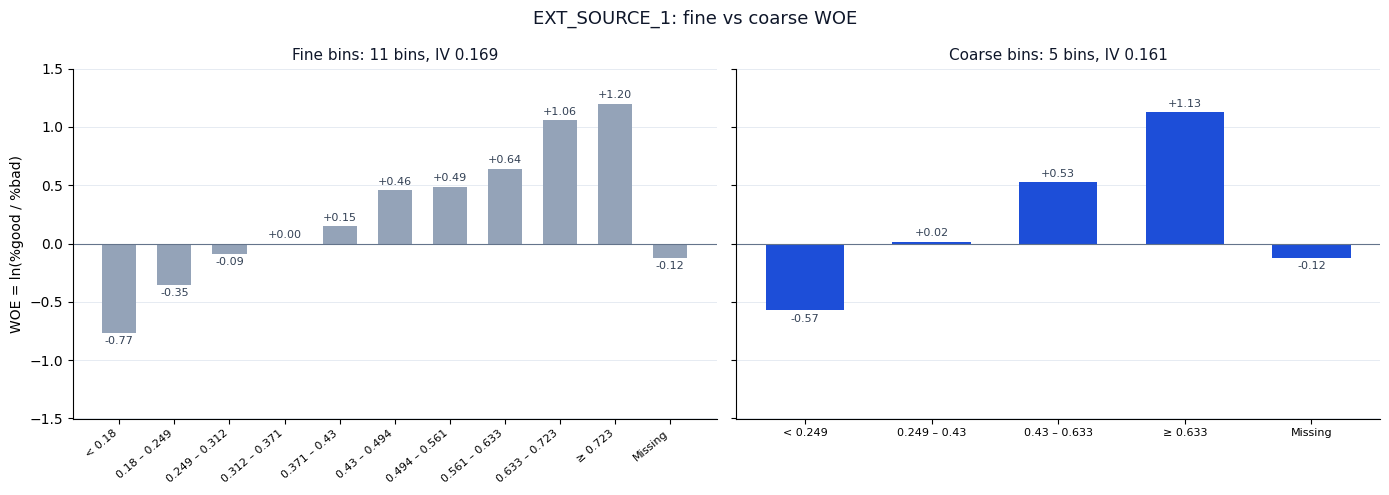

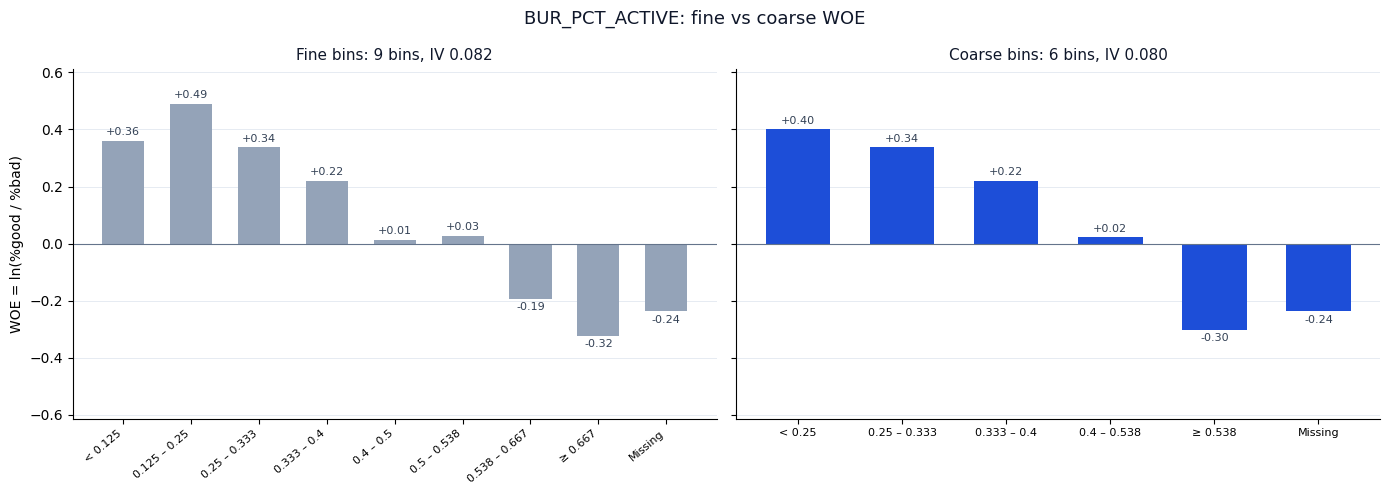

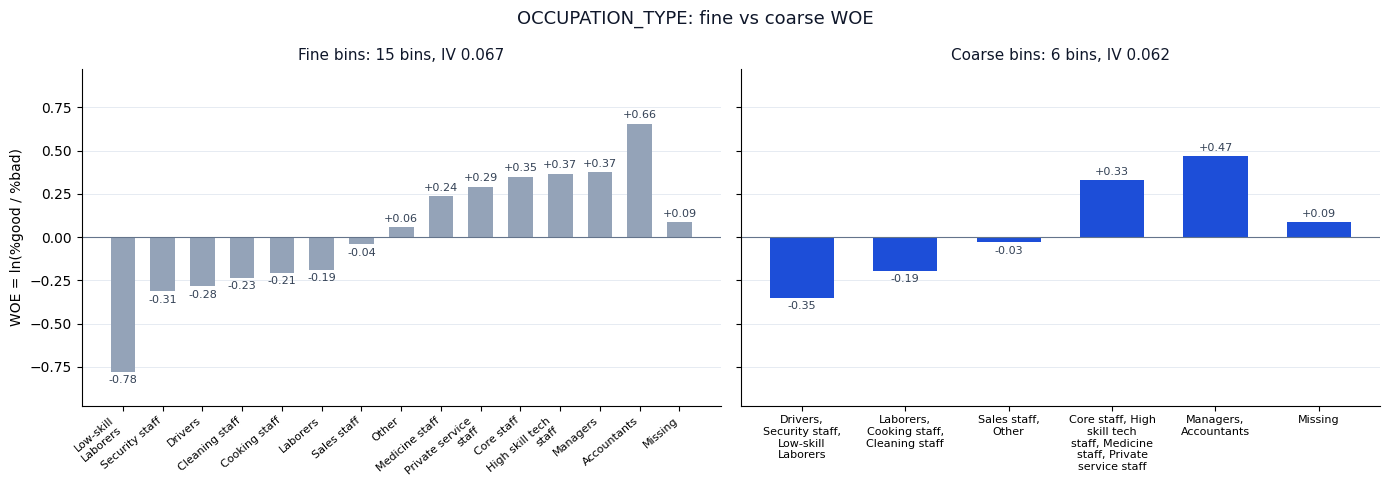

In [17]:
def wrap(label, width=16):
    return '\n'.join(textwrap.wrap(label, width, break_long_words=False)) or label

def plot_fine_vs_coarse(feature):
    fine_t, coarse_t = fine_tables[feature], coarse_tables[feature]
    lim = 1.25 * max(fine_t['woe'].abs().max(), coarse_t['woe'].abs().max())
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, table, title, color in [(axes[0], fine_t, 'Fine bins', '#94A3B8'), (axes[1], coarse_t, 'Coarse bins', '#1D4ED8')]:
        x = np.arange(len(table))
        ax.bar(x, table['woe'], width=0.62, color=color)
        for xi, w in zip(x, table['woe']):
            ax.text(xi, w + (0.02 * lim if w >= 0 else -0.02 * lim), f'{w:+.2f}', ha='center', va='bottom' if w >= 0 else 'top', fontsize=8, color='#334155')
        ax.axhline(0, color='#64748B', linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels([wrap(l) for l in table.index], rotation=0 if len(table) <= 6 else 40, ha='center' if len(table) <= 6 else 'right', fontsize=8)
        ax.set_title(f"{title}: {len(table)} bins, IV {table['iv'].sum():.3f}", fontsize=11, color='#0F172A')
        ax.set_ylim(-lim, lim)
        ax.grid(axis='y', color='#E2E8F0', linewidth=0.6); ax.set_axisbelow(True)
        for side in ('top', 'right'): ax.spines[side].set_visible(False)
    axes[0].set_ylabel('WOE = ln(%good / %bad)')
    fig.suptitle(f'{feature}: fine vs coarse WOE', fontsize=13, color='#0F172A')
    fig.tight_layout()
    plt.show()

nominal_final = [f for f in final_features if fine_info[f]['model']['kind'] == 'nominal']
plot_variables = [v for v in ['EXT_SOURCE_1', 'BUR_PCT_ACTIVE'] if v in final_features]
for v in ['EXT_SOURCE_1', 'BUR_PCT_ACTIVE']:
    if v not in final_features: print(f'{v} is not in the final set, so it is not plotted.')
if nominal_final:
    plot_variables.append(max(nominal_final, key=lambda f: coarse_results[f]['coarse_iv']))
else:
    print('No text variable is in the final set.')
for v in plot_variables:
    plot_fine_vs_coarse(v)

## Step 13 – WOE encoding

Replaces each value of the final variables with the WOE of its coarse bin, for both train and test. A test value with no train bin (an unseen category with no "Other" bin, or Missing where train had none) gets WOE 0, and the count is printed.

In [18]:
train_woe = pd.DataFrame(index=train_df.index)
test_woe = pd.DataFrame(index=test_df.index)
unmapped_rows = {}
for feature in final_features:
    groups, info = coarse_results[feature]['groups'], fine_info[feature]
    woe_by_id = {i: g['woe'] for g in groups for i in g['ids']}
    train_woe[feature] = info['train_ids'].map(woe_by_id)
    test_values = info['test_ids'].map(woe_by_id)
    unmapped_rows[feature] = int(test_values.isna().sum())
    test_woe[feature] = test_values.fillna(0.0)

    # check: rebuilding the table from the coarse labels gives the same WOE as the bin groups
    train_labels = info['train_ids'].map(coarse_models[feature])
    rebuilt = woe_table_from_bins(train_labels, train_df['TARGET'], order=list(coarse_tables[feature].index))
    assert np.allclose(rebuilt['woe'], coarse_tables[feature]['woe']), feature
assert not train_woe.isna().any().any(), 'train rows without a WOE'
print('Final variables:', len(final_features))
print('Test rows given WOE 0 because they have no train bin:', {f: n for f, n in unmapped_rows.items() if n} or 'none')
display(train_woe.describe().T[['mean', 'std', 'min', 'max']].round(3))

Final variables: 20
Test rows given WOE 0 because they have no train bin: {'DAYS_LAST_PHONE_CHANGE': 1}


,mean,std,min,max
EXT_SOURCE_1,0.072,0.447,-0.573,1.126
BUR_DEBT_RATIO,0.037,0.301,-0.530,0.350
DAYS_EMPLOYED,0.035,0.301,-0.242,0.637
BUR_PCT_ACTIVE,0.033,0.288,-0.301,0.401
BUR_OLDEST_DAYS,0.031,0.277,-0.460,0.369
BUR_MOST_RECENT_DAYS,0.028,0.262,-0.508,0.321
OCCUPATION_TYPE,0.025,0.253,-0.350,0.468
DAYS_LAST_PHONE_CHANGE,0.026,0.257,-0.220,0.515
BUR_N_CLOSED,0.020,0.223,-0.279,0.297
FLAG_DOCUMENT_3,0.016,0.204,-0.117,0.329


## Step 14 – Logistic regression

Fits logistic regression on the WOE-encoded variables from Step 13. In the scorecard (Step 16), a bin's points are −(coefficient × WOE) × factor. The intercept goes into the base points instead of being split across variables, which gives the same total score.

Since WOE = ln(%good / %bad), a higher WOE means a safer bin. So every coefficient should be negative, otherwise safer bins get fewer points. For example, BUR_N_CLOSED has a positive coefficient, which would give applicants with 5+ closed loans (bad rate 7.2%) about 16 points less than those with none (bad rate 12.2%).

To fix this, we remove the variable with the most positive coefficient and refit until all are negative. 6 bureau variables are removed and 14 remain, and test AUC only changes from 0.692 to 0.689.

In [19]:
def fit_lr(features):
    return LogisticRegression(solver='liblinear', max_iter=1000, random_state=453).fit(train_woe[features], train_df['TARGET'])

first_features = list(final_features)
first_lr = fit_lr(first_features)

# Remove the most positive coefficient and refit until all are negative
removed_round = {}
model_features = list(first_features)
while True:
    lr = fit_lr(model_features)
    coefficients = pd.Series(lr.coef_[0], index=model_features)
    if (coefficients <= 0).all():
        break
    worst = coefficients.idxmax()
    removed_round[worst] = len(removed_round) + 1
    model_features.remove(worst)
final_features = model_features      # all later steps use this list and this lr

coef_table = pd.DataFrame({'First fit': pd.Series(first_lr.coef_[0], index=first_features),
                           'Final model': coefficients}).reindex(first_features)
coef_table['Status'] = ['Kept' if f in final_features else f'Removed (round {removed_round[f]})' for f in first_features]
coef_table.loc['Intercept'] = [first_lr.intercept_[0], lr.intercept_[0], '']
display(coef_table.style
        .format({'First fit': '{:+.3f}', 'Final model': '{:+.3f}'}, na_rep='–')
        .map(lambda v: 'color: #DC2626; font-weight: bold' if isinstance(v, float) and v > 0 else '', subset=['First fit'])
        .set_caption(f'Coefficients ({len(first_features)} variables → {len(final_features)}; positive in red). '
                     f"Test AUC {roc_auc_score(test_df['TARGET'], first_lr.predict_proba(test_woe[first_features])[:, 1]):.3f} → "
                     f"{roc_auc_score(test_df['TARGET'], lr.predict_proba(test_woe[final_features])[:, 1]):.3f}"))

,First fit,Final model,Status
EXT_SOURCE_1,-0.757,-0.763,Kept
BUR_DEBT_RATIO,-0.755,-0.528,Kept
DAYS_EMPLOYED,-0.580,-0.595,Kept
BUR_PCT_ACTIVE,-0.735,-0.230,Kept
BUR_OLDEST_DAYS,-0.242,–,Removed (round 6)
BUR_MOST_RECENT_DAYS,-0.619,-0.515,Kept
OCCUPATION_TYPE,-0.741,-0.722,Kept
DAYS_LAST_PHONE_CHANGE,-0.634,-0.633,Kept
BUR_N_CLOSED,+0.965,–,Removed (round 1)
FLAG_DOCUMENT_3,-0.662,-0.672,Kept


## Step 15 – Score scaling

Converts the model's log-odds into points: 600 points at 19:1 good-to-bad odds, 20 points to double the odds. Higher scores mean lower default risk.

In [20]:
# Course score scale: 600 score, 19:1 good-to-bad odds, 20 points per doubling.
base_score, base_good_bad_odds, points_to_double_odds = 600, 19, 20

# Higher scores represent lower predicted default risk.
factor = points_to_double_odds / np.log(2)
base_points = base_score + factor * (-lr.intercept_[0] - np.log(base_good_bad_odds))


def score_woe_frame(woe_frame):
    # Convert the model log-odds into the course credit-score scale.
    logit_bad = (
        lr.predict_log_proba(woe_frame)[:, 1]
        - lr.predict_log_proba(woe_frame)[:, 0]
    )
    return base_score + factor * (-logit_bad - np.log(base_good_bad_odds))

train_score = score_woe_frame(train_woe[final_features])
test_score = score_woe_frame(test_woe[final_features])
print('Score summary:')
print(pd.concat([
    pd.Series(train_score, name='train'),
    pd.Series(test_score, name='test')
], axis=1).describe().round(1))

Score summary:
         train     test
count  80515.0  34507.0
mean     585.9    585.9
std       21.1     21.2
min      524.3    522.2
25%      570.9    570.8
50%      584.8    584.9
75%      599.7    599.8
max      678.2    665.8


## Step 16 – Scorecard points table

Shows the points each coarse bin adds to the score: points = −factor × coefficient × WOE. Bins are listed in value order within each variable (Missing last).

In [21]:
# Each row shows the points contributed by one coarse WOE bin.
coefficient_lookup = dict(zip(final_features, lr.coef_[0]))
scorecard_rows = []
for feature in final_features:
    coefficient = coefficient_lookup[feature]
    for bin_name, row in coarse_tables[feature].iterrows():
        scorecard_rows.append({'Variable': feature, 'Bin': bin_name, 'Bin_Order': int(row['bin_order']), 'Count': int(row['count']),
                               'Bad_Rate': row['bad'] / row['count'], 'WOE': row['woe'], 'IV': row['iv'],
                               'Points': -factor * coefficient * row['woe']})
scorecard_table = pd.DataFrame(scorecard_rows).sort_values(['Variable', 'Bin_Order']).reset_index(drop=True)
print('Base points:', round(base_points, 1))
display(scorecard_table.drop(columns='Bin_Order').style.format({'Bad_Rate': '{:.2%}', 'WOE': '{:.4f}', 'IV': '{:.4f}', 'Points': '{:.1f}'}).hide(axis='index'))

Base points: 580.1


Variable,Bin,Count,Bad_Rate,WOE,IV,Points
AMT_ANNUITY,"< 9,000 (incl. Missing)",6498,7.31%,0.2853,0.0059,3.1
AMT_ANNUITY,"9,000 – 14,778",25655,7.78%,0.2173,0.0138,2.3
AMT_ANNUITY,"14,778 – 16,875",8056,9.89%,-0.0456,0.0002,-0.5
AMT_ANNUITY,"≥ 16,875",40306,10.85%,-0.1491,0.0118,-1.6
AMT_CREDIT,"< 139,346",8052,6.78%,0.3661,0.0116,8.5
AMT_CREDIT,"139,346 – 180,000",4970,8.07%,0.1783,0.0018,4.1
AMT_CREDIT,"180,000 – 254,700",18646,8.82%,0.0814,0.0015,1.9
AMT_CREDIT,"254,700 – 306,000",16611,9.55%,-0.0070,0.0000,-0.2
AMT_CREDIT,"≥ 306,000",32236,10.75%,-0.1384,0.0081,-3.2
BUR_DEBT_RATIO,< 0.117,26915,6.88%,0.3498,0.0355,5.3


## Step 17 – Model performance

Train AUC (0.687) and test AUC (0.689) are almost equal, so the model is not overfitting. However, both are rated Poor (0.6–0.7), as 13 of the 14 variables are Weak by IV. Only EXT_SOURCE_1, a normalised score from an external data source, is Medium.

The confusion matrix uses cutoff 560 on the Step 15 scores. Applicants scoring below 560 are predicted to default.

Accuracy at 560 is 84.3%, but accuracy is misleading here because most applicants repay. Approving everyone would give 90.5% accuracy without catching a single defaulter. Recall (90.5% of good payers approved) and specificity (24.6% of defaulters caught) are more useful, and the defaulter F1 is similar on train and test (0.237 vs 0.229).

Data,AUC,Rating,Accuracy at 560
Train,0.687,Poor,84.4%
Test,0.689,Poor,84.3%


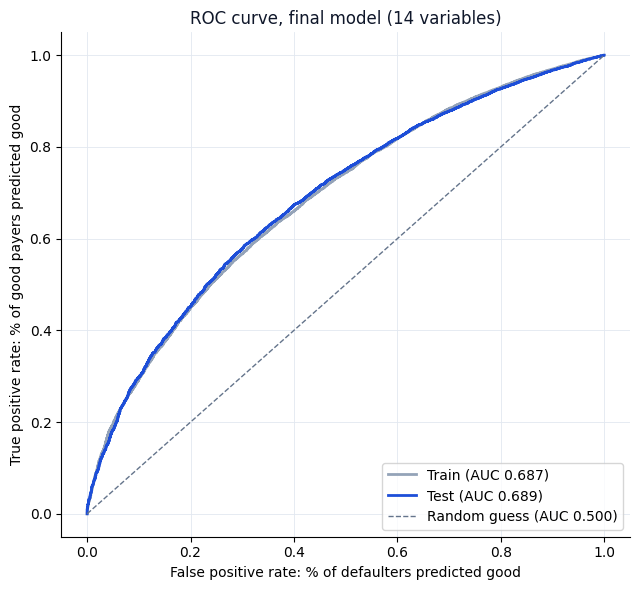

,Predicted good payer,Predicted defaulter
Actual good payer,"66,043 (TP)","6,828 (FN)"
Actual defaulter,"5,702 (FP)","1,942 (TN)"


,Predicted good payer,Predicted defaulter
Actual good payer,"28,268 (TP)","2,963 (FN)"
Actual defaulter,"2,471 (FP)",805 (TN)


Data,Class,Precision,Recall,F1,Count
Train,Good payer,0.921,0.906,0.913,"72,871"
Train,Defaulter,0.221,0.254,0.237,"7,644"
Test,Good payer,0.920,0.905,0.912,"31,231"
Test,Defaulter,0.214,0.246,0.229,"3,276"


In [22]:
from sklearn.metrics import roc_curve, precision_recall_fscore_support

train_probability = lr.predict_proba(train_woe[final_features])[:, 1]   # predicted chance of default
test_probability = lr.predict_proba(test_woe[final_features])[:, 1]
train_auc = roc_auc_score(train_df['TARGET'], train_probability)
test_auc = roc_auc_score(test_df['TARGET'], test_probability)

def auc_band(auc):                                   # course AUC rating
    for upper, label in [(0.6, 'Not useful'), (0.7, 'Poor'), (0.8, 'Fair'), (0.9, 'Good')]:
        if auc < upper:
            return label
    return 'Excellent'

cutoff_score = 560                                   # approve if the Step 15 score is at least 560
datasets = {'Train': (train_df['TARGET'].to_numpy(), train_probability, np.asarray(train_score)),
            'Test': (test_df['TARGET'].to_numpy(), test_probability, np.asarray(test_score))}

auc_table = pd.DataFrame([{'Data': name, 'AUC': roc_auc_score(y, p), 'Rating': auc_band(roc_auc_score(y, p)),
                           'Accuracy at 560': ((s < cutoff_score).astype(int) == y).mean()} for name, (y, p, s) in datasets.items()])
display(auc_table.style.format({'AUC': '{:.3f}', 'Accuracy at 560': '{:.1%}'}).hide(axis='index').set_caption('AUC'))

# ROC curve: positive class = good payer, so pass 1 - TARGET and the chance of being good
fig, ax = plt.subplots(figsize=(6.5, 6))
for (name, (y, p, _)), color in zip(datasets.items(), ['#94A3B8', '#1D4ED8']):
    fpr, tpr, _ = roc_curve(1 - y, 1 - p)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC {roc_auc_score(y, p):.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='#64748B', linewidth=1, label='Random guess (AUC 0.500)')
ax.set_xlabel('False positive rate: % of defaulters predicted good')
ax.set_ylabel('True positive rate: % of good payers predicted good')
ax.set_title(f'ROC curve, final model ({len(final_features)} variables)', fontsize=12, color='#0F172A')
ax.legend(loc='lower right')
ax.grid(color='#E2E8F0', linewidth=0.6); ax.set_axisbelow(True)
for side in ('top', 'right'): ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

# Confusion matrix (good payer = positive) and PCC measures at cutoff 560
metric_rows = []
for name, (y, p, s) in datasets.items():
    predicted_bad = (s < cutoff_score).astype(int)
    tp, fn, fp, tn = confusion_matrix(y, predicted_bad, labels=[0, 1]).ravel()
    matrix = pd.DataFrame([[f'{tp:,} (TP)', f'{fn:,} (FN)'], [f'{fp:,} (FP)', f'{tn:,} (TN)']],
                          index=['Actual good payer', 'Actual defaulter'], columns=['Predicted good payer', 'Predicted defaulter'])
    display(matrix.style.set_caption(f'{name}: confusion matrix at cutoff {cutoff_score}'))
    precision, recall, f1, support = precision_recall_fscore_support(y, predicted_bad, labels=[0, 1], zero_division=0)
    for k, label in enumerate(['Good payer', 'Defaulter']):
        metric_rows.append({'Data': name, 'Class': label, 'Precision': precision[k], 'Recall': recall[k], 'F1': f1[k], 'Count': support[k]})
display(pd.DataFrame(metric_rows).style.format({'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1': '{:.3f}', 'Count': '{:,}'})
        .hide(axis='index').set_caption(f'PCC measures at cutoff {cutoff_score}'))

## Step 18 – Model tuning

Since the model is rated Poor, we test whether tuning improves it. We try the four tuning approaches: adding or removing characteristics, substituting characteristics, changing attribute ranges, and changing the number of attributes. Version A is the first fit from Step 14 and B is the final model. C to I each change one thing and get the same sign check as B.

Each version approves the same 89.1% of test applicants (the share approved at cutoff 560), so the versions can be compared on test AUC, the train–test gap (stability) and defaulters approved. A version is only allowed if every bin holds at least 5% of train and no coefficient is positive.

In [23]:
def tune_build(features, min_bin_pct=0.05, woe_gap=0.05):
    """Coarse-class and WOE-encode a list of variables with the Step 12 rules, using different settings."""
    results = {f: coarse_class(fine_info[f]['fine_groups'], fine_info[f]['model'], n_train,
                               min_bin_pct=min_bin_pct, woe_gap=woe_gap) for f in features}
    kept = sorted([f for f in features if results[f]['status'] == 'Kept'], key=lambda f: -results[f]['coarse_iv'])
    tr, te = pd.DataFrame(index=train_df.index), pd.DataFrame(index=test_df.index)
    for f in kept:
        woe_by_id = {i: g['woe'] for g in results[f]['groups'] for i in g['ids']}
        tr[f] = fine_info[f]['train_ids'].map(woe_by_id)
        te[f] = fine_info[f]['test_ids'].map(woe_by_id).fillna(0.0)
    return results, kept, tr, te


def tune_fit(features, tr, fix_signs=True):
    """Fit logistic regression; if fix_signs, apply the Step 14 rule (remove the most positive coefficient, refit)."""
    features = list(features)
    while True:
        model = LogisticRegression(solver='liblinear', max_iter=1000, random_state=453).fit(tr[features], train_df['TARGET'])
        coefs = pd.Series(model.coef_[0], index=features)
        if not fix_signs or (coefs <= 0).all():
            return features, model
        features.remove(coefs.idxmax())


approval_rate = float((np.asarray(test_score) >= cutoff_score).mean())     # share approved by the final model at cutoff 560


def tune_row(version, method, change, pool, min_bin_pct=0.05, woe_gap=0.05, fix_signs=True, top_n=None):
    results, kept, tr, te = tune_build(pool, min_bin_pct, woe_gap)
    features, model = tune_fit(kept, tr, fix_signs)
    if top_n:                                   # keep the top N by coarse IV from the sign-checked list, then refit
        features, model = tune_fit(features[:top_n], tr, fix_signs)
    p_tr, p_te = model.predict_proba(tr[features])[:, 1], model.predict_proba(te[features])[:, 1]
    approved = p_te <= np.quantile(p_te, approval_rate)
    auc_tr, auc_te = roc_auc_score(train_df['TARGET'], p_tr), roc_auc_score(test_df['TARGET'], p_te)
    smallest = min(results[f]['min_bin_pct'] for f in features)
    positives = int((model.coef_[0] > 0).sum())
    return {'Version': version, 'Tuning approach': method, 'What changed': change,
            'Variables': len(features), 'Bins': sum(results[f]['n_bins'] for f in features),
            'Smallest bin': smallest, 'Train AUC': auc_tr, 'Test AUC': auc_te, 'Train − test': auc_tr - auc_te,
            'Defaulters approved': int(test_df['TARGET'][approved].sum()),
            'Meets rules': 'Yes' if smallest >= 0.05 and positives == 0 else
                           ('No: positive coefficients' if positives else 'No: bin under 5%')}


swap_pool = [f for f in corr_survivors if f != 'BUR_N_CLOSED'] + ['BUR_N_CONSUMER']
tuning_table = pd.DataFrame([
    tune_row('A', 'Starting point', 'All 20 variables, no sign check', corr_survivors, fix_signs=False),
    tune_row('B', 'Remove characteristics', 'Sign check (Step 14 model)', corr_survivors),
    tune_row('C', 'Remove characteristics', 'Top 10 variables by IV', corr_survivors, top_n=10),
    tune_row('D', 'Remove characteristics', 'Top 8 variables by IV', corr_survivors, top_n=8),
    tune_row('E', 'Substitute characteristics', 'BUR_N_CONSUMER instead of BUR_N_CLOSED', swap_pool),
    tune_row('F', 'Change attribute ranges', 'Minimum bin size 10%', corr_survivors, min_bin_pct=0.10),
    tune_row('G', 'Change attribute ranges', 'Minimum bin size 3%', corr_survivors, min_bin_pct=0.03),
    tune_row('H', 'Number of attributes', 'Merge bins with WOE gap < 0.20', corr_survivors, woe_gap=0.20),
    tune_row('I', 'Number of attributes', 'Never merge on similar WOE', corr_survivors, woe_gap=0.0),
])
display(tuning_table.style
        .format({'Smallest bin': '{:.1%}', 'Train AUC': '{:.3f}', 'Test AUC': '{:.3f}', 'Train − test': '{:+.3f}', 'Defaulters approved': '{:,}'})
        .apply(lambda row: ['font-weight: bold' if row['Version'] == 'B' else ''] * len(row), axis=1)
        .hide(axis='index').set_caption(f'Tuning versions (each approves {approval_rate:.1%} of test applicants; chosen version in bold)'))

# The chosen version must be the model already fitted in Step 14 (used by Steps 15, 16 and 19)
chosen = tuning_table.set_index('Version').loc['B']
assert chosen['Variables'] == len(final_features) and np.isclose(chosen['Test AUC'], test_auc)

Version,Tuning approach,What changed,Variables,Bins,Smallest bin,Train AUC,Test AUC,Train − test,Defaulters approved,Meets rules
A,Starting point,"All 20 variables, no sign check",20,105,6.2%,0.690,0.692,-0.002,"2,435",No: positive coefficients
B,Remove characteristics,Sign check (Step 14 model),14,72,6.2%,0.687,0.689,-0.002,"2,471",Yes
C,Remove characteristics,Top 10 variables by IV,10,53,7.6%,0.679,0.681,-0.003,"2,481",Yes
D,Remove characteristics,Top 8 variables by IV,8,47,7.6%,0.674,0.678,-0.003,"2,503",Yes
E,Substitute characteristics,BUR_N_CONSUMER instead of BUR_N_CLOSED,14,72,6.2%,0.687,0.689,-0.002,"2,471",Yes
F,Change attribute ranges,Minimum bin size 10%,15,57,10.0%,0.679,0.681,-0.001,"2,510",Yes
G,Change attribute ranges,Minimum bin size 3%,14,80,3.2%,0.688,0.690,-0.002,"2,477",No: bin under 5%
H,Number of attributes,Merge bins with WOE gap < 0.20,14,53,6.2%,0.685,0.687,-0.002,"2,485",Yes
I,Number of attributes,Never merge on similar WOE,14,80,6.2%,0.687,0.689,-0.002,"2,470",Yes


**Result: version B.**

* **A:** highest test AUC (0.692), but gives safer bins fewer points.
* **C, D, F, H:** lower test AUC and more defaulters approved.
* **E:** same model as B, because BUR_N_CONSUMER is removed for a positive coefficient.
* **G:** test AUC 0.690, but more defaulters approved (2,477 vs 2,471) and bins under 5%.
* **I:** same test AUC as B and 1 fewer defaulter approved, but 8 more bins.

B ties with I on test AUC and uses fewer bins, so we keep the Step 14 model.

## Step 19 – Cutoff evaluation (560)

Tests an approval cutoff of 560 on the historical applicants: scores at or above 560 are approved, lower scores are treated as predicted defaults.

In [24]:
# Applicants at or above the cutoff are approved; lower scores are classified as bad.
score_cutoff = 560
for title, actual, scores in [
    ('Training', train_df['TARGET'], train_score),
    ('Test', test_df['TARGET'], test_score)
]:
    approved = scores >= score_cutoff
    print(
        f'{title}: approved {approved.sum():,} ({approved.mean():.1%}); '
        f'actual defaults among approved {actual[approved].sum():,}; '
        f'actual bad rate among approved {actual[approved].mean():.2%}'
    )

Training: approved 71,745 (89.1%); actual defaults among approved 5,702; actual bad rate among approved 7.95%
Test: approved 30,739 (89.1%); actual defaults among approved 2,471; actual bad rate among approved 8.04%


**Other cutoffs (test data).** A higher cutoff catches more defaulters (higher specificity) but approves fewer good payers (lower recall).

In [25]:
y_test = test_df['TARGET'].to_numpy()
cutoff_rows = [{'Cutoff': 'None (approve all)', 'Approved': 1.0, 'Recall (good payers approved)': 1.0,
                'Specificity (defaulters caught)': 0.0, 'Defaulter F1': 0.0, 'Accuracy': 1 - y_test.mean()}]
for score in (540, 560, 580, 600):
    predicted_bad = (np.asarray(test_score) < score).astype(int)
    _, recall, f1, _ = precision_recall_fscore_support(y_test, predicted_bad, labels=[0, 1], zero_division=0)
    cutoff_rows.append({'Cutoff': str(score), 'Approved': 1 - predicted_bad.mean(), 'Recall (good payers approved)': recall[0],
                        'Specificity (defaulters caught)': recall[1], 'Defaulter F1': f1[1],
                        'Accuracy': (predicted_bad == y_test).mean()})
display(pd.DataFrame(cutoff_rows).style
        .format('{:.1%}', subset=['Approved', 'Recall (good payers approved)', 'Specificity (defaulters caught)', 'Accuracy'])
        .format('{:.3f}', subset=['Defaulter F1'])
        .hide(axis='index').set_caption('Test data at different cutoffs'))

Cutoff,Approved,Recall (good payers approved),Specificity (defaulters caught),Defaulter F1,Accuracy
None (approve all),100.0%,100.0%,0.0%,0.000,90.5%
540,99.5%,99.6%,1.4%,0.027,90.3%
560,89.1%,90.5%,24.6%,0.229,84.3%
580,59.0%,61.6%,66.0%,0.248,62.0%
600,24.7%,26.5%,91.9%,0.206,32.7%


# Cutoff, pricing and profitability (Steps 20–22)


## Step 20 – Cutoff calculations and calibration

Same steps as the Module 11.5 "Cutoff Calculations" exercise and the Session 11 Lab:

* odds of good:bad at a score = 19 × 2^((score − 600) / 20), and probability of default p = 1 / (1 + odds)
* approvals = applicants scoring at or above the cutoff
* expected defaults = sum of each approved applicant's own p (Session 11 Lab), compared with the actual defaults

The band table then checks calibration: if the actual and predicted bad rates are close, the score can be read as a probability of default, which Step 21 needs for pricing.

In [ ]:
def score_to_odds(score):
    """Good:bad odds implied by a score on our scale (600 = 19:1, 20 points to double the odds)."""
    return base_good_bad_odds * 2 ** ((np.asarray(score) - base_score) / points_to_double_odds)


def score_to_pd(score):
    return 1 / (1 + score_to_odds(score))


test_eval = pd.DataFrame({'score': np.asarray(test_score), 'bad': test_df['TARGET'].to_numpy(),
                          'amt_credit': test_df['AMT_CREDIT'].to_numpy()})
test_eval['pd_score'] = score_to_pd(test_eval['score'])

# --- cutoff calculations (Module 11.5 / Session 11 Lab) ---
cutoff_rows = []
for c in [540, 550, 560, 570, 580, 590, 600]:
    approved = test_eval['score'] >= c
    cutoff_rows.append({'Cutoff': c, 'Odds at cutoff': float(score_to_odds(c)), 'PD at cutoff': float(score_to_pd(c)),
                        'Approved': int(approved.sum()), 'Approval rate': approved.mean(),
                        'Expected defaults': test_eval.loc[approved, 'pd_score'].sum(),
                        'Actual defaults': int(test_eval.loc[approved, 'bad'].sum()),
                        'Bad rate (approved)': test_eval.loc[approved, 'bad'].mean()})
cutoff_calc = pd.DataFrame(cutoff_rows)
display(cutoff_calc.style.format({'Odds at cutoff': '{:.2f}', 'PD at cutoff': '{:.1%}', 'Approved': '{:,}',
                                  'Approval rate': '{:.1%}', 'Expected defaults': '{:,.0f}', 'Actual defaults': '{:,}',
                                  'Bad rate (approved)': '{:.2%}'}).hide(axis='index')
        .set_caption('Cutoff calculations on the test data'))

# --- score bands and calibration ---
band_edges = [-np.inf, 540, 560, 580, 600, np.inf]
band_names = ['< 540', '540–559', '560–579', '580–599', '≥ 600']
test_eval['band'] = pd.cut(test_eval['score'], bins=band_edges, labels=band_names, right=False)

band_table = test_eval.groupby('band', observed=False).agg(
    Applicants=('bad', 'size'), Bads=('bad', 'sum'), Actual_bad_rate=('bad', 'mean'),
    Predicted_bad_rate=('pd_score', 'mean'), Avg_loan=('amt_credit', 'mean'))
band_table['Share'] = band_table['Applicants'] / len(test_eval)
band_table['Goods per bad'] = (band_table['Applicants'] - band_table['Bads']) / band_table['Bads']
display(band_table[['Applicants', 'Share', 'Bads', 'Actual_bad_rate', 'Predicted_bad_rate', 'Goods per bad', 'Avg_loan']].style
        .format({'Share': '{:.1%}', 'Actual_bad_rate': '{:.2%}', 'Predicted_bad_rate': '{:.2%}',
                 'Goods per bad': '{:.1f}', 'Avg_loan': '{:,.0f}'})
        .set_caption('Test applicants by score band (predicted = average PD from the score)'))

## Step 21 – Interest rate determination

Module 7.1: lending profit is the net interest margin minus losses from defaults, so "interest rates charged on loans need to be aligned with default risk" and cover "operating costs". For a group of loans with bad rate *b*, only good loans pay interest, but every loan has to be funded and serviced, and each bad loan loses LGD of its balance. Per unit lent:

* break-even rate = (b × LGD + cost of funds + operating cost) ÷ (1 − b)
* target rate = (b × LGD + cost of funds + operating cost + target margin) ÷ (1 − b)

The inputs below are **assumptions** (the dataset has no pricing data). LGD is 60% because a start-up loan has no business assets or trading history behind it; this is conservative because TARGET records payment difficulties, and some of those borrowers recover. A band whose target rate is above `max_rate` is declined, which is what sets the cutoff.

In [ ]:
pricing_assumptions = {
    'LGD': 0.60,               # share of the balance lost when a loan goes bad (unsecured)
    'cost_of_funds': 0.03,     # bank funding cost per year (deposit rate in the Module 7.1 NIM example)
    'operating_cost': 0.02,    # making, processing and collecting the loan, per year
    'target_margin': 0.02,     # profit target per year on each unit lent
    'max_rate': 0.18,          # highest rate the bank will charge a start-up (affordability, reputation)
}
A = pricing_assumptions
carry = A['cost_of_funds'] + A['operating_cost']


def breakeven_rate(bad_rate, a=A):
    return (bad_rate * a['LGD'] + a['cost_of_funds'] + a['operating_cost']) / (1 - bad_rate)


def target_rate(bad_rate, a=A):
    return (bad_rate * a['LGD'] + a['cost_of_funds'] + a['operating_cost'] + a['target_margin']) / (1 - bad_rate)


# Offered rate per approved tier: at least the target rate, set in market-friendly steps.
# Tier A is priced above its target but below the flat rate, so the safest borrowers are not overcharged.
policy_rates = {'≥ 600': 0.11, '580–599': 0.13, '560–579': 0.175}

pricing_table = band_table[['Applicants', 'Actual_bad_rate']].copy()
pricing_table['Break-even rate'] = breakeven_rate(pricing_table['Actual_bad_rate'])
pricing_table['Target rate'] = target_rate(pricing_table['Actual_bad_rate'])
pricing_table['Within max rate'] = np.where(pricing_table['Target rate'] <= A['max_rate'], 'Yes', 'No – decline')
pricing_table['Offered rate'] = pd.Series(policy_rates)
display(pricing_table.style.format({'Actual_bad_rate': '{:.2%}', 'Break-even rate': '{:.1%}', 'Target rate': '{:.1%}',
                                    'Offered rate': '{:.1%}'}, na_rep='Declined')
        .set_caption('Rate each score band must charge'))
for band, rate in policy_rates.items():
    if rate < pricing_table.loc[band, 'Target rate']:
        print(f'Warning: {band} is offered {rate:.1%}, below its target rate {pricing_table.loc[band, "Target rate"]:.1%}')

book_560 = test_eval[test_eval['score'] >= 560]
flat_rate = np.ceil(target_rate(book_560['bad'].mean()) * 200) / 200     # rounded up to the next 0.5%
print(f"Single flat rate for the whole 560 book (bad rate {book_560['bad'].mean():.2%}): "
      f"break-even {breakeven_rate(book_560['bad'].mean()):.1%}, target {target_rate(book_560['bad'].mean()):.1%} -> flat rate {flat_rate:.1%}")

## Step 22 – Cutoff selection and profitability

Module 11.4 method, per 10,000 applicants:

* **Revenue** = good loans approved × revenue per good loan, where revenue per good loan = loan × (rate − cost of funds − operating cost), the net interest margin
* **Expense** = defaults approved × loss per default, where loss per default = loan × (LGD + cost of funds + operating cost)
* **Net profit** = revenue − expense

The loan size is the average `AMT_CREDIT` of the test applicants. Two pricing policies are compared:

* **Flat rate**: every approved borrower pays the single target rate of the 560 book (Step 21).
* **Tiered**: each approved band pays its offered rate from Step 21; bands below 560 could be charged at most `max_rate`.

The **swap ratio** (Session 11 Lab) is the number of good payers turned away for each default avoided when the cutoff moves up from 560. Raising the cutoff pays only if one default costs more than the profit on that many good loans.

In [ ]:
avg_loan = test_eval['amt_credit'].mean()
scale = 10_000 / len(test_eval)


def book_profit(cutoff, rate_of, a=A):
    """Module 11.4: revenue, expense and net profit per 10,000 applicants per year.
    rate_of: Series with the interest rate charged to each applicant."""
    c = a['cost_of_funds'] + a['operating_cost']
    approved = test_eval['score'] >= cutoff
    good, bad = approved & (test_eval['bad'] == 0), approved & (test_eval['bad'] == 1)
    revenue = (rate_of[good] - c).sum() * avg_loan * scale            # good loans x net interest margin
    expense = bad.sum() * avg_loan * (a['LGD'] + c) * scale            # defaults x loss per default
    return {'approved': approved.sum(), 'bads': bad.sum(), 'revenue': revenue, 'expense': expense,
            'profit': revenue - expense}


tier_rate = test_eval['band'].astype(str).map(policy_rates).fillna(A['max_rate'])
flat = pd.Series(flat_rate, index=test_eval.index)
base = test_eval['score'] >= 560
rows = []
for cutoff in [0, 540, 550, 560, 570, 580, 590, 600]:
    f, t = book_profit(cutoff, flat), book_profit(cutoff, tier_rate)
    now = test_eval['score'] >= cutoff
    goods_lost = int(((base & ~now) & (test_eval['bad'] == 0)).sum())
    bads_avoided = int(((base & ~now) & (test_eval['bad'] == 1)).sum())
    rows.append({'Cutoff': 'None' if cutoff == 0 else str(cutoff),
                 'Approved per 10k': f['approved'] * scale, 'Approval rate': f['approved'] / len(test_eval),
                 'Bad rate (approved)': f['bads'] / f['approved'],
                 'Goods lost per bad avoided (vs 560)': goods_lost / bads_avoided if bads_avoided else np.nan,
                 'Flat: revenue (m)': f['revenue'] / 1e6, 'Flat: expense (m)': f['expense'] / 1e6,
                 'Flat: net profit (m)': f['profit'] / 1e6,
                 'Tiered: revenue (m)': t['revenue'] / 1e6, 'Tiered: expense (m)': t['expense'] / 1e6,
                 'Tiered: net profit (m)': t['profit'] / 1e6})
profit_table = pd.DataFrame(rows)
money_cols = [c for c in profit_table.columns if c.endswith('(m)')]
display(profit_table.style
        .format({'Approval rate': '{:.1%}', 'Bad rate (approved)': '{:.2%}', 'Approved per 10k': '{:,.0f}',
                 'Goods lost per bad avoided (vs 560)': '{:.1f}', **{c: '{:,.1f}' for c in money_cols}}, na_rep='–')
        .hide(axis='index')
        .set_caption(f'Per 10,000 applicants per year (average loan {avg_loan:,.0f}; flat rate {flat_rate:.1%}; '
                     f"tiers {', '.join(f'{b} {r:.1%}' for b, r in policy_rates.items())})"))

best_flat = profit_table.loc[profit_table['Flat: net profit (m)'].idxmax(), 'Cutoff']
best_tier = profit_table.loc[profit_table['Tiered: net profit (m)'].idxmax(), 'Cutoff']
print(f'Most profitable cutoff: flat rate -> {best_flat}, tiered rates -> {best_tier}')

# break-even swap ratio: how many good loans' profit one default wipes out
for label, rate in [(f'flat {flat_rate:.1%}', flat_rate), (f"Tier C {policy_rates['560–579']:.1%}", policy_rates['560–579'])]:
    print(f"At {label}, one default costs as much as the profit on {(A['LGD'] + carry) / (rate - carry):.1f} good loans")

# profit added by each score band under tiered pricing
contrib = []
for band in band_names:
    in_band = test_eval['band'] == band
    rate = policy_rates.get(band, A['max_rate'])
    g, b = int((in_band & (test_eval['bad'] == 0)).sum()), int((in_band & (test_eval['bad'] == 1)).sum())
    contrib.append({'Band': band, 'Rate charged': rate,
                    'Net profit per 10k applicants (m)': (g * (rate - carry) - b * (A['LGD'] + carry)) * avg_loan * scale / 1e6})
display(pd.DataFrame(contrib).style.format({'Rate charged': '{:.1%}', 'Net profit per 10k applicants (m)': '{:,.1f}'})
        .hide(axis='index').set_caption('Profit added by each score band (tiered pricing)'))

# sensitivity: net profit by cutoff for different LGD values (rates held fixed)
sens = []
for lgd in [0.45, 0.60, 0.75]:
    a = dict(A, LGD=lgd)
    sens.append({'LGD': lgd, **{f'Cutoff {c}': book_profit(c, tier_rate, a)['profit'] / 1e6 for c in [540, 560, 580, 600]}})
display(pd.DataFrame(sens).style.format('{:,.1f}', subset=[f'Cutoff {c}' for c in [540, 560, 580, 600]])
        .format({'LGD': '{:.0%}'}).hide(axis='index').set_caption('Sensitivity: tiered net profit (m) per 10,000 applicants'))
tier_c = test_eval['band'] == '560–579'
g_c, b_c = (tier_c & (test_eval['bad'] == 0)).sum(), (tier_c & (test_eval['bad'] == 1)).sum()
print(f"Tier C stays profitable at {policy_rates['560–579']:.1%} while LGD is below "
      f"{g_c * (policy_rates['560–579'] - carry) / b_c - carry:.0%}")

fig, ax = plt.subplots(figsize=(7, 4))
x = profit_table[profit_table['Cutoff'] != 'None']
ax.plot(x['Cutoff'].astype(int), x['Flat: net profit (m)'], marker='o', color='#94A3B8', label=f'Flat {flat_rate:.1%}')
ax.plot(x['Cutoff'].astype(int), x['Tiered: net profit (m)'], marker='o', color='#1D4ED8', label='Tiered rates')
ax.axvline(560, linestyle='--', color='#64748B', linewidth=1)
ax.set_xlabel('Cutoff score'); ax.set_ylabel('Net profit per 10,000 applicants (m)')
ax.set_title('Net profit by cutoff', fontsize=12, color='#0F172A'); ax.legend()
ax.grid(color='#E2E8F0', linewidth=0.6); ax.set_axisbelow(True)
for side in ('top', 'right'): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

**Decision rule.** The cutoff sits where the rate a band would need goes above the highest rate the bank is willing to charge. The 540–559 band needs about 25%, above the 18% cap, and loses money even at 18%, so it is declined. The 560–579 band needs about 17%, within the cap, so it is approved at 17.5% (Tier C). Under a single flat rate the 560–579 band loses money and the best cutoff moves up to 580. **Cutoff 560 is the right choice only together with tiered pricing.**

# Step 23 – Scorecard walkthrough with examples

Same method as Session 11 Lab Ex Q1 ("manually calculate the score and approval status"): look up the bin each application value falls in, read that bin's points from the Step 16 scorecard table, and add them to the base points. Then:

* odds of good:bad = 19 × 2^((score − 600) / 20), probability of default = 1 / (1 + odds)
* approve if the score is at least the 560 cutoff, and assign the Step 21 rate tier

The same applicant is also scored by the fitted model (`score_woe_frame`) to confirm the hand calculation gives the same total. The characteristics where the applicant loses the most points against the best bin are listed as reason codes.

In [ ]:
def lookup_bin(feature, value):
    """Coarse bin label and WOE for one raw value, using the training bins from Steps 7 and 12."""
    model = fine_info[feature]['model']
    series = pd.Series([value], dtype=object if model['kind'] == 'nominal' else float)
    fine_id = int(assign_fine_bins(series, model).iloc[0])
    woe_by_id = {i: g['woe'] for g in coarse_results[feature]['groups'] for i in g['ids']}
    return coarse_models[feature].get(fine_id, 'No train bin'), woe_by_id.get(fine_id, 0.0)


def decision(score):
    if score >= 600: return f"Approve – Tier A ({policy_rates['≥ 600']:.1%})"
    if score >= 580: return f"Approve – Tier B ({policy_rates['580–599']:.1%})"
    if score >= 560: return f"Approve – Tier C ({policy_rates['560–579']:.1%})"
    return 'Decline'


best_points = scorecard_table.groupby('Variable')['Points'].max()


def walk_through(name, applicant):
    rows, woes = [], {}
    for f in final_features:
        value = applicant.get(f, np.nan)
        label, woe = lookup_bin(f, value)
        points = -factor * coefficient_lookup[f] * woe          # same formula as the Step 16 points table
        woes[f] = woe
        rows.append({'Characteristic': f, 'App Value': 'Missing' if pd.isna(value) else value, 'Bin': label,
                     'WOE': woe, 'Points': points, 'Short of best bin': best_points[f] - points})
    card = pd.DataFrame(rows)
    total = base_points + card['Points'].sum()
    model_total = float(score_woe_frame(pd.DataFrame([woes])[final_features])[0])
    assert abs(total - model_total) < 1e-6, (total, model_total)
    odds = float(score_to_odds(total))
    print(f"\n{name}\n  Score = base {base_points:.1f} + characteristics {card['Points'].sum():+.1f} = {total:.1f} "
          f"(model check {model_total:.1f})\n  Odds {odds:.1f}:1 good:bad, probability of default {1 / (1 + odds):.1%}"
          f"\n  Decision at cutoff {cutoff_score}: {decision(total)}")
    display(card.style.format({'WOE': '{:+.3f}', 'Points': '{:+.1f}', 'Short of best bin': '{:.1f}'}).hide(axis='index'))
    print('  Reason codes (largest point shortfalls):', ', '.join(card.nlargest(3, 'Short of best bin')['Characteristic']))
    return total


examples = {
    'Applicant A – accountant opening a bookkeeping practice': {
        'EXT_SOURCE_1': 0.55, 'BUR_DEBT_RATIO': 0.25, 'DAYS_EMPLOYED': -4000, 'BUR_PCT_ACTIVE': 0.30,
        'BUR_MOST_RECENT_DAYS': -400, 'OCCUPATION_TYPE': 'Accountants', 'DAYS_LAST_PHONE_CHANGE': -1400,
        'FLAG_DOCUMENT_3': 1, 'NAME_CONTRACT_TYPE': 'Cash loans', 'AMT_ANNUITY': 12000, 'OWN_CAR_AGE': 5,
        'AMT_CREDIT': 220000, 'BUR_MAX_AMT_MAX_OVERDUE': 0, 'DAYS_ID_PUBLISH': -3500},
    'Applicant B – sales staff opening a retail kiosk': {
        'EXT_SOURCE_1': np.nan, 'BUR_DEBT_RATIO': 0.50, 'DAYS_EMPLOYED': -2000, 'BUR_PCT_ACTIVE': 0.45,
        'BUR_MOST_RECENT_DAYS': -150, 'OCCUPATION_TYPE': 'Sales staff', 'DAYS_LAST_PHONE_CHANGE': -800,
        'FLAG_DOCUMENT_3': 1, 'NAME_CONTRACT_TYPE': 'Cash loans', 'AMT_ANNUITY': 18000, 'OWN_CAR_AGE': np.nan,
        'AMT_CREDIT': 280000, 'BUR_MAX_AMT_MAX_OVERDUE': 1000, 'DAYS_ID_PUBLISH': -2500},
    'Applicant C – new-to-credit labourer starting a food stall (no bureau record)': {
        'EXT_SOURCE_1': np.nan, 'BUR_DEBT_RATIO': np.nan, 'DAYS_EMPLOYED': -500, 'BUR_PCT_ACTIVE': np.nan,
        'BUR_MOST_RECENT_DAYS': np.nan, 'OCCUPATION_TYPE': 'Laborers', 'DAYS_LAST_PHONE_CHANGE': -200,
        'FLAG_DOCUMENT_3': 1, 'NAME_CONTRACT_TYPE': 'Cash loans', 'AMT_ANNUITY': 20000, 'OWN_CAR_AGE': np.nan,
        'AMT_CREDIT': 400000, 'BUR_MAX_AMT_MAX_OVERDUE': np.nan, 'DAYS_ID_PUBLISH': -400},
}
example_scores = {name: walk_through(name, app) for name, app in examples.items()}

# what-if for Applicant C: a smaller loan with a smaller instalment
what_if = dict(examples['Applicant C – new-to-credit labourer starting a food stall (no bureau record)'],
               AMT_CREDIT=130000, AMT_ANNUITY=8000)
walk_through('What-if: Applicant C asks for 130,000 with an 8,000 instalment', what_if)

# Appendix: Week 10 exploratory IV (not used in the model)
This analysis ran on the full data before the train/test split and was superseded by Steps 7–9, so nothing in Steps 1–17 depends on it.

### Week 10 Preparation

**Do fine classing and characteristic screening on your project data**

Use the functions in the earlier part of the lab to calculate WOE and IV on a subset of your poject data.

**DIY Q4: Calculate IV for a subset of your variables**

Based on correlation to the target variable, pick the 30 characteristics with the highest correlation and calculate their IV.

In [26]:
def woe_iv(data):
    working_data = data.copy()
    working_data['Bin_Range'] = working_data['Bin_Range'].astype('object')
    working_data['Bin_Range'] = working_data['Bin_Range'].fillna('Missing')
    variable_data = pd.DataFrame()
    variable_data['Bin_Range'] = working_data.groupby(by='Bin_Range', as_index=False).count()['Bin_Range']
    variable_data['Count'] = working_data.groupby(by='Bin_Range', as_index=False).count()['BAD']
    variable_data['Events'] = working_data.groupby(by='Bin_Range', as_index=False).sum()['BAD']
    variable_data['Non_Events'] = variable_data['Count'] - variable_data['Events']
    variable_data['%_of_Events'] = variable_data['Events']/sum(variable_data['Events'])
    variable_data['%_of_Non_Events'] = variable_data['Non_Events']/sum(variable_data['Non_Events'])
    variable_data['WOE'] = np.log(variable_data['%_of_Non_Events'] / variable_data['%_of_Events'])
    variable_data['IV'] = (variable_data['%_of_Non_Events']-variable_data['%_of_Events']) * variable_data['WOE']
    variable_data['total_IV'] = variable_data['IV'].sum()
    return(variable_data)

screen_df = merged_df.drop(columns=['SK_ID_CURR', 'DAYS_BIRTH'])
corr_matrix = screen_df.select_dtypes('number').corr()
ranked = corr_matrix['TARGET'].abs().sort_values(ascending=False)
top_30 = ranked.iloc[1:31].reset_index()

screen_df['DAYS_LAST_PHONE_CHANGE'] = screen_df['DAYS_LAST_PHONE_CHANGE'].fillna(0)

def predictive_power(iv):
    if iv < 0.02:
        return 'Not useful'
    if iv < 0.1:
        return 'Weak'
    if iv < 0.3:
        return 'Medium'
    if iv < 0.5:
        return 'Strong'
    return 'Suspicious'

bin_count = 20
rows = []
for variable in top_30['index']:
    woe_bin_data = screen_df[[variable]].copy()
    woe_bin_data['BAD'] = screen_df['TARGET']

    if woe_bin_data.groupby(variable).count().shape[0] > bin_count:
        woe_bin_data['Bin_Range'] = pd.qcut(woe_bin_data[variable], q=bin_count, duplicates='drop')
    else:
        woe_bin_data['Bin_Range'] = pd.cut(woe_bin_data[variable], bins=[-1, 0, 1, 2, 3, 100])

    iv = woe_iv(woe_bin_data).loc[0, 'total_IV']
    rows.append({'Variable': variable, 'Correlation': round(corr_matrix.loc[variable, 'TARGET'], 4),
                 'IV': round(iv, 4), 'Predictive_Power': predictive_power(iv)})

iv_table = pd.DataFrame(rows).sort_values('IV', ascending=False).reset_index().drop(columns=['index'])
display(iv_table)

,Variable,Correlation,IV,Predictive_Power
0,EXT_SOURCE_1,-0.1530,0.1720,Medium
1,BUR_DEBT_RATIO,0.0961,0.0992,Weak
2,BUR_PCT_ACTIVE,0.0822,0.0895,Weak
3,BUR_OLDEST_DAYS,0.0838,0.0855,Weak
4,BUR_MOST_RECENT_DAYS,0.0450,0.0836,Weak
5,DAYS_LAST_PHONE_CHANGE,0.0667,0.0611,Weak
6,REGION_RATING_CLIENT_W_CITY,0.0645,0.0485,Weak
7,BUR_N_CLOSED,-0.0482,0.0471,Weak
8,AGE,-0.0596,0.0462,Weak
9,REGION_RATING_CLIENT,0.0612,0.0441,Weak
